
# STEAM ANALYTICS
## Análisis exploratorio de datos y estadística aplicada

### 1. Introducción

Este notebook tiene como objetivo explorar, analizar e interpretar los datos recolectados mediante Steam API y procesados a través de la arquitectura Medallion.

Se utilizarán los datos de la capa Gold para identificar patrones, relaciones, tendencias temporales y características del comportamiento de usuarios y videojuegos.

### 2. Objetivos

- Comprender la estructura y calidad de los datos.
- Analizar distribuciones y relaciones entre variables.
- Estudiar las características de usuarios y videojuegos.
- Investigar patrones de recomendaciones y reseñas.
- Analizar cohortes de usuarios.
- Estudiar tendencias temporales.
- Formular y contrastar hipótesis estadísticas.
- Obtener hallazgos respaldados por evidencia.

### 3. Fuentes de información

Los datos se obtendrán de:

`Medallion/3.Gold/Data/`

Se utilizarán dimensiones, tablas de hechos y agregaciones mensuales.

### 4. Metodología

El trabajo seguirá un enfoque exploratorio y estadístico, utilizando Python, Pandas, NumPy, Matplotlib, Seaborn y herramientas de inferencia estadística.

### 5. Alcance y limitaciones

El análisis se realizará sobre la muestra de datos recolectada. Las reseñas tienen un límite de extracción configurado de hasta 100 por juego, por lo que los resultados no representan necesariamente la totalidad de la actividad de Steam.

Las asociaciones estadísticas no se interpretarán automáticamente como relaciones causales.


In [10]:

# ============================================================
# STEAM ANALYTICS
# NOTEBOOK 1 - EDA + ESTADÍSTICA
# CELDA 1: CONFIGURACIÓN Y CARGA DE DATOS
# ============================================================

from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# ------------------------------------------------------------
# 1. GOOGLE DRIVE
# ------------------------------------------------------------

if not Path("/content/drive/MyDrive").exists():
    from google.colab import drive
    drive.mount("/content/drive")

print("Google Drive disponible.")

# ------------------------------------------------------------
# 2. RUTAS DEL PROYECTO
# ------------------------------------------------------------

ROOT = Path(
    "/content/drive/MyDrive/"
    "Infraestructura-de-ciencia-de-datos"
)

GOLD_DATA = ROOT / "Medallion" / "3.Gold" / "Data"

ANALYTICS = ROOT / "Analytics"

REPORTS = ANALYTICS / "Reports" / "EDA_Estadistica"

VISUALIZATIONS = (
    ANALYTICS / "Visualizations" / "EDA_Estadistica"
)

REPORTS.mkdir(parents=True, exist_ok=True)
VISUALIZATIONS.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 3. CONFIGURACIÓN GENERAL
# ------------------------------------------------------------

warnings.filterwarnings("default")

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.3f}".format)

sns.set_theme(
    style="whitegrid",
    context="notebook"
)

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 110

# ------------------------------------------------------------
# 4. ARCHIVOS DE ENTRADA
# ------------------------------------------------------------

ARCHIVOS = {
    "resenas": "fact_resenas.parquet",
    "novedades": "fact_novedades.parquet",
    "agregaciones": "agg_juego_mes.parquet",
    "usuarios": "dim_usuarios.parquet",
    "juegos": "dim_juegos.parquet",
    "fechas": "dim_fecha.parquet",
    "idiomas": "dim_idioma.parquet",
    "hardware": "dim_hardware.parquet"
}

# ------------------------------------------------------------
# 5. VERIFICACIÓN DE EXISTENCIA
# ------------------------------------------------------------

print("=" * 75)
print("STEAM ANALYTICS - CARGA DE DATOS GOLD")
print("=" * 75)

faltantes = []

for nombre, archivo in ARCHIVOS.items():

    ruta = GOLD_DATA / archivo

    if not ruta.exists():
        faltantes.append(archivo)
        print(f"[FALTANTE] {archivo}")
    else:
        print(f"[OK] {archivo}")

if faltantes:
    raise FileNotFoundError(
        f"Faltan archivos Gold: {faltantes}"
    )

# ------------------------------------------------------------
# 6. CARGA DE DATAFRAMES
# ------------------------------------------------------------

datos = {}

for nombre, archivo in ARCHIVOS.items():

    ruta = GOLD_DATA / archivo

    datos[nombre] = pd.read_parquet(ruta)

# Variables individuales para facilitar el análisis
df_resenas = datos["resenas"]
df_novedades = datos["novedades"]
df_agregaciones = datos["agregaciones"]
df_usuarios = datos["usuarios"]
df_juegos = datos["juegos"]
df_fechas = datos["fechas"]
df_idiomas = datos["idiomas"]
df_hardware = datos["hardware"]

# ------------------------------------------------------------
# 7. RESUMEN DE CARGA
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("RESUMEN DE DATASETS")
print("=" * 75)

for nombre, df in datos.items():

    memoria = (
        df.memory_usage(deep=True).sum() / (1024 ** 2)
    )

    print(
        f"{nombre:20} | "
        f"Filas: {len(df):>9,} | "
        f"Columnas: {len(df.columns):>3} | "
        f"Memoria: {memoria:>8.2f} MB"
    )

print("\n" + "=" * 75)
print("CARGA COMPLETADA CORRECTAMENTE")
print("=" * 75)


Google Drive disponible.
STEAM ANALYTICS - CARGA DE DATOS GOLD
[OK] fact_resenas.parquet
[OK] fact_novedades.parquet
[OK] agg_juego_mes.parquet
[OK] dim_usuarios.parquet
[OK] dim_juegos.parquet
[OK] dim_fecha.parquet
[OK] dim_idioma.parquet
[OK] dim_hardware.parquet


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



RESUMEN DE DATASETS
resenas              | Filas:    46,990 | Columnas:  33 | Memoria:    41.15 MB
novedades            | Filas:     5,039 | Columnas:  14 | Memoria:     2.79 MB
agregaciones         | Filas:    13,208 | Columnas:   7 | Memoria:     1.31 MB
usuarios             | Filas:    39,000 | Columnas:  28 | Memoria:    40.75 MB
juegos               | Filas:     5,001 | Columnas:   5 | Memoria:     0.50 MB
fechas               | Filas:     7,897 | Columnas:  11 | Memoria:     1.33 MB
idiomas              | Filas:        31 | Columnas:   2 | Memoria:     0.00 MB
hardware             | Filas:     2,837 | Columnas:   6 | Memoria:     0.92 MB

CARGA COMPLETADA CORRECTAMENTE


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [3]:
# ============================================================
# CELDA 2: INVENTARIO DE VARIABLES
# ============================================================

perfiles = []

for nombre, df in datos.items():

    for columna in df.columns:

        serie = df[columna]

        muestras = serie.dropna().head(2).tolist()

        # Para evitar errores con tipos no hashables como listas o numpy arrays,
        # los convertimos a tuplas para poder calcular 'nunique' correctamente.
        try:
            valores_unicos = int(serie.nunique(dropna=True))
        except TypeError:
            # Si falla por no ser hashable, convertimos los elementos no nulos a tuplas
            serie_hashable = serie.dropna().apply(lambda x: tuple(x) if isinstance(x, (list, np.ndarray)) else x)
            valores_unicos = int(serie_hashable.nunique())

        perfiles.append({
            "dataset": nombre,
            "variable": columna,
            "tipo": str(serie.dtype),
            "registros": len(df),
            "nulos": int(serie.isna().sum()),
            "porcentaje_nulos": round(
                serie.isna().mean() * 100, 2
            ),
            "valores_unicos": valores_unicos,
            "ejemplos": str(muestras)[:150]
        })

inventario = pd.DataFrame(perfiles)

# Mostrar inventario completo
display(
    inventario.sort_values(
        ["dataset", "variable"]
    ).reset_index(drop=True)
)

# Exportar documentación de variables
salida = REPORTS / "inventario_variables_gold.csv"

inventario.to_csv(
    salida,
    index=False,
    encoding="utf-8-sig"
)

print(f"\nInventario exportado: {salida}")

,dataset,variable,tipo,registros,nulos,porcentaje_nulos,valores_unicos,ejemplos
0,agregaciones,cantidad_novedades,int64,13208,0,0.000,43,"[2, 1]"
1,agregaciones,cantidad_resenas,int64,13208,0,0.000,83,"[0, 0]"
2,agregaciones,game_key,int64,13208,0,0.000,498,"[0, 0]"
3,agregaciones,month,int64,13208,0,0.000,12,"[5, 11]"
4,agregaciones,month_key,int64,13208,0,0.000,194,"[202005, 202011]"
...,...,...,...,...,...,...,...,...
101,usuarios,steamid,object,39000,0,0.000,39000,"['UNKNOWN', '76561197960272407']"
102,usuarios,timecreated,float64,39000,5912,15.160,33087,"[1063350433.0, 1063355607.0]"
103,usuarios,timecreated_numeric,float64,39000,5912,15.160,33087,"[1063350433.0, 1063355607.0]"
104,usuarios,timecreated_parsed,"datetime64[ns, UTC]",39000,5912,15.160,33087,"[Timestamp('2003-09-12 07:07:13+0000', tz='UTC..."



Inventario exportado: /content/drive/MyDrive/Infraestructura-de-ciencia-de-datos/Analytics/Reports/EDA_Estadistica/inventario_variables_gold.csv


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



## 3. Inspección detallada de variables analíticas

### Objetivo

Examinar en profundidad las variables disponibles en los datasets de la capa Gold para identificar cuáles pueden utilizarse en los análisis exploratorios, estadísticos y posteriores experimentos de Ciencia de Datos.

### Alcance

Se inspeccionarán los siguientes conjuntos de datos:

- **Reseñas:** variables de recomendación, contenido textual, votos, fechas e idioma.
- **Novedades:** títulos, contenido, fechas de publicación y fuentes.
- **Usuarios:** fechas de creación de cuentas y características disponibles de los perfiles.
- **Juegos:** identificadores y atributos del catálogo.
- **Idiomas:** códigos de idioma disponibles.
- **Hardware:** características de los equipos registrados.

### Procedimiento

Para cada variable se analizarán:

- Nombre y tipo de dato.
- Cantidad y porcentaje de valores nulos.
- Cantidad de valores únicos.
- Ejemplos representativos.
- Disponibilidad y utilidad para futuros análisis.

Se prestará especial atención a las variables relacionadas con el texto de las reseñas, las recomendaciones, la utilidad de las publicaciones y las fechas.

### Criterios de análisis

La inspección permitirá:

1. Identificar posibles variables objetivo para modelos predictivos.
2. Reconocer atributos relevantes para el análisis estadístico.
3. Determinar la disponibilidad y calidad de los textos para NLP.
4. Detectar limitaciones de información y valores faltantes.
5. Definir qué preguntas de investigación pueden responderse con los datos existentes.

### Consideraciones metodológicas

- No se modificarán los archivos originales de Gold.
- No se eliminarán registros durante esta etapa.
- No se asumirán significados de variables sin verificar su contenido.
- Los identificadores personales no se expondrán en los informes.
- Las variables se seleccionarán según su pertinencia analítica y calidad.

### Resultado esperado

Un inventario detallado de las variables disponibles que servirá como base para diseñar el análisis exploratorio, formular hipótesis estadísticas y preparar los futuros experimentos de NLP y Machine Learning.


In [5]:
# ============================================================
# 3. INSPECCIÓN DETALLADA DE VARIABLES ANALÍTICAS
# ============================================================

DATASETS_CLAVE = [
    "resenas",
    "novedades",
    "usuarios",
    "juegos",
    "idiomas",
    "hardware"
]

# Evitar exponer identificadores o datos de perfil
CAMPOS_SENSIBLES = [
    "steamid",
    "personaname",
    "realname",
    "avatar",
    "profile"
]

for nombre in DATASETS_CLAVE:

    df = datos[nombre]

    print("\n" + "=" * 90)
    print(f"DATASET: {nombre.upper()}")
    print("=" * 90)

    filas = []

    for columna in df.columns:

        serie = df[columna]

        es_sensible = any(
            palabra in columna.lower()
            for palabra in CAMPOS_SENSIBLES
        )

        ejemplos = (
            serie.dropna()
            .head(2)
            .astype(str)
            .tolist()
        )

        if es_sensible:
            ejemplos = ["OMITIDO"]

        # Mostrar muestras únicamente de texto relevante
        if any(
            palabra in columna.lower()
            for palabra in ["review", "title", "contents", "comment"]
        ):
            ejemplos = [
                str(valor)[:180]
                for valor in serie.dropna().head(2).tolist()
            ]

        # Manejo robusto para tipos de datos no hashables al calcular 'nunique'
        try:
            valores_unicos = int(serie.nunique(dropna=True))
        except TypeError:
            serie_hashable = serie.dropna().apply(lambda x: tuple(x) if isinstance(x, (list, np.ndarray)) else x)
            valores_unicos = int(serie_hashable.nunique())

        filas.append({
            "variable": columna,
            "tipo": str(serie.dtype),
            "nulos": int(serie.isna().sum()),
            "% nulos": round(
                serie.isna().mean() * 100, 2
            ),
            "valores_unicos": valores_unicos,
            "ejemplos": str(ejemplos)[:220]
        })

    perfil = pd.DataFrame(filas)

    display(perfil)

print("\nINSPECCIÓN DETALLADA FINALIZADA")


DATASET: RESENAS


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,variable,tipo,nulos,% nulos,valores_unicos,ejemplos
0,recommendationid,string,0,0.000,46990,"['100011358', '10001661']"
1,user_key,int64,0,0.000,39000,"['1232', '6975']"
2,game_key,int64,0,0.000,497,"['277', '250']"
3,date_key,int64,0,0.000,4413,"['20210926', '20140502']"
4,language_key,int64,0,0.000,30,"['7', '7']"
5,hardware_key,int64,0,0.000,2837,"['0', '0']"
6,steamid,string,0,0.000,39000,['OMITIDO']
7,appid,Int64,0,0.000,497,"['11260', '10120']"
8,review,object,0,0.000,43440,['The core and concept of the game is interest...
9,timestamp_created,int64,0,0.000,46934,"['1632687726', '1399072047']"



DATASET: NOVEDADES


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,variable,tipo,nulos,% nulos,valores_unicos,ejemplos
0,gid,string,0,0.000,5039,"['1806064758740099', '1805431065309991']"
1,game_key,int64,0,0.000,99,"['1', '1']"
2,date_key,int64,0,0.000,1625,"['20250728', '20250716']"
3,appid,Int64,0,0.000,104,"['10', '10']"
4,title,string,0,0.000,3979,['Counter-Strike Source soars to 13-year Steam...
5,url,object,0,0.000,5039,['https://steamstore-a.akamaihd.net/news/exter...
6,is_external_url,bool,0,0.000,2,"['True', 'True']"
7,author,object,0,0.000,201,"['editor@pcgamesn.com', '']"
8,feed_label,object,0,0.000,16,"['PCGamesN', 'Rock, Paper, Shotgun']"
9,feed_name,object,0,0.000,18,"['PCGamesN', 'Rock, Paper, Shotgun']"


... (11 outputs left out)


DATASET: HARDWARE


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,variable,tipo,nulos,% nulos,valores_unicos,ejemplos
0,hardware_key,int64,0,0.000,2837,"['0', '1']"
1,hardware.os,object,0,0.000,57,"['UNKNOWN', 'Windows 10']"
2,hardware.cpu_name,object,0,0.000,577,"['UNKNOWN', 'Intel(R) Core(TM) i7-7700K CPU @ ..."
3,hardware.adapter_description,object,2,0.070,457,"['UNKNOWN', 'NVIDIA GeForce GTX 1660 Ti']"
4,hardware.system_ram,object,0,0.000,1447,"['UNKNOWN', '16324.0']"
5,hardware.vram_size,object,0,0.000,354,"['UNKNOWN', '5966.0']"



INSPECCIÓN DETALLADA FINALIZADA



## 4. Diagnóstico de disponibilidad y calidad de variables

### 4.1. Resultados generales

La inspección de los ocho datasets de Gold permitió identificar las variables disponibles para el desarrollo de los análisis exploratorios y estadísticos.

El conjunto de reseñas contiene 46.990 registros y 33 columnas. Presenta información textual, recomendaciones, actividad de usuarios, fechas, idiomas, interacciones y características de hardware.

El conjunto de novedades contiene 5.039 publicaciones y 14 columnas, principalmente asociadas a identificadores, títulos, fuentes y fechas de publicación.

### 4.2. Variables principales identificadas

**Reseñas**
- `review`: contenido textual.
- `voted_up`: recomendación positiva o negativa.
- `votes_up`: votos positivos recibidos.
- `votes_funny`: votos divertidos.
- `weighted_vote_score`: puntuación ponderada.
- `comment_count`: cantidad de comentarios.
- `author.playtime_at_review`: tiempo jugado al momento de la reseña.
- `timestamp_created_parsed`: fecha de creación.

**Usuarios**
- `account_created_year`: año de creación de cuenta.
- `communityvisibilitystate`: visibilidad del perfil.
- `loccountrycode`: país declarado, cuando está disponible.

**Juegos**
- `appid`: identificador natural del juego.
- `name`: nombre del videojuego.

**Idioma y hardware**
- `language_key`: asociación con la dimensión de idiomas.
- `hardware_key`: asociación con configuraciones de hardware.

**Novedades**
- `title`: título de la publicación.
- `feed_label`: fuente editorial.
- `timestamp_publicacion`: fecha de publicación.
- `tags`: etiquetas disponibles.

### 4.3. Calidad y disponibilidad

Se identificaron las siguientes limitaciones:

- 5.912 usuarios sin fecha de creación disponible.
- 43.657 reseñas sin información de hardware.
- 65 valores faltantes en `author.playtime_at_review`.
- 45.946 valores faltantes en `author.deck_playtime_at_review`.
- 46.972 reseñas sin respuesta del desarrollador.
- 4.341 novedades sin etiquetas.

La ausencia de información deberá considerarse al seleccionar muestras y variables para cada análisis.

### 4.4. Variables objetivo potenciales

Se identifica `voted_up` como variable objetivo principal para futuros experimentos de clasificación.

La variable `review` será la fuente principal para los experimentos de NLP.

La utilidad de las reseñas podrá estudiarse mediante `votes_up` y otras variables de interacción, siempre que su distribución y calidad permitan construir un problema predictivo adecuado.

### 4.5. Consideraciones metodológicas

- Los análisis de cohortes utilizarán únicamente usuarios con fecha de creación conocida.
- Los análisis de hardware excluirán el registro desconocido.
- Se evaluará la distribución de idiomas antes de seleccionar técnicas de NLP.
- Se evitará utilizar variables posteriores a la publicación como predictores de la recomendación original.
- No se interpretarán asociaciones como relaciones causales.
- Los resultados representarán la muestra recolectada y no la totalidad de Steam.

### 4.6. Resultado de la inspección

Esta disponibilidad de variables permite desarrollar análisis descriptivos, comparaciones entre grupos, estudios temporales, análisis de cohortes y experimentos de clasificación de texto.

La siguiente etapa consistirá en caracterizar cuantitativamente el conjunto de reseñas, evaluar la distribución de la variable objetivo y examinar la representatividad de la muestra.



## 5. Caracterización cuantitativa de la muestra

### 5.1. Objetivo

Caracterizar cuantitativamente el conjunto de reseñas recolectadas para conocer su composición, distribución y cobertura temporal.

Esta etapa permitirá establecer una línea base estadística para los análisis exploratorios posteriores.

### 5.2. Dimensiones de análisis

Se estudiarán las siguientes dimensiones:

- **Recomendaciones:** distribución de reseñas positivas y negativas.
- **Usuarios:** cantidad de usuarios representados.
- **Videojuegos:** cantidad de juegos con reseñas y distribución de registros por juego.
- **Idiomas:** composición lingüística de las reseñas.
- **Temporalidad:** período cubierto y evolución mensual.
- **Contenido textual:** textos vacíos y repetidos.
- **Interacción:** votos positivos, votos divertidos, comentarios y puntuaciones.
- **Tiempo de juego:** distribución del tiempo registrado al momento de publicar una reseña.

### 5.3. Consideraciones sobre la muestra

La extracción de reseñas se configuró con un máximo de 100 registros por juego, priorizando las reseñas más recientes.

Por lo tanto:

- La muestra no representa necesariamente todas las reseñas existentes en Steam.
- Los juegos tienen diferentes cantidades de registros.
- Las diferencias de volumen no deben interpretarse directamente como diferencias de popularidad global.
- Las comparaciones entre juegos deberán considerar el tamaño de muestra disponible.

### 5.4. Metodología

Se utilizarán estadísticas descriptivas, frecuencias absolutas y relativas, percentiles y agrupaciones temporales.

También se revisará la integridad del texto y la distribución de las variables de interacción.

No se realizarán todavía pruebas de hipótesis ni se establecerán relaciones causales.

### 5.5. Resultados esperados

- Resumen cuantitativo de la muestra.
- Distribución de recomendaciones.
- Distribución por idioma.
- Cantidad de reseñas por videojuego.
- Cobertura temporal mensual.
- Estadísticas descriptivas de interacción.
- Indicadores de calidad del contenido textual.

Los resultados se exportarán a la carpeta `Analytics/Reports/EDA_Estadistica/`.


In [6]:

# ============================================================
# STEAM ANALYTICS
# NOTEBOOK 1 - CELDA 4
# CARACTERIZACIÓN CUANTITATIVA DE LA MUESTRA
# ============================================================

print("=" * 85)
print("CARACTERIZACIÓN CUANTITATIVA - STEAM ANALYTICS")
print("=" * 85)

# ------------------------------------------------------------
# 1. VALIDACIÓN DE VARIABLES NECESARIAS
# ------------------------------------------------------------

REQUERIDAS = {
    "resenas": [
        "recommendationid",
        "user_key",
        "game_key",
        "language_key",
        "review",
        "voted_up",
        "timestamp_created_parsed",
        "votes_up",
        "votes_funny",
        "comment_count",
        "weighted_vote_score",
        "author.playtime_at_review"
    ],
    "idiomas": [
        "language_key",
        "language_code"
    ],
    "juegos": [
        "game_key",
        "name"
    ]
}

for nombre, columnas in REQUERIDAS.items():

    faltantes = set(columnas) - set(datos[nombre].columns)

    if faltantes:
        raise ValueError(
            f"Faltan columnas en {nombre}: {sorted(faltantes)}"
        )

# ------------------------------------------------------------
# 2. PREPARACIÓN
# ------------------------------------------------------------

resenas = df_resenas.copy()

resenas["fecha_analisis"] = pd.to_datetime(
    resenas["timestamp_created_parsed"],
    errors="coerce",
    utc=True
)

# Normalizar textos únicamente para medir su calidad.
textos = (
    resenas["review"]
    .fillna("")
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
)

textos_validos = textos[textos != ""]

# ------------------------------------------------------------
# 3. MÉTRICAS GENERALES
# ------------------------------------------------------------

total = len(resenas)

usuarios_validos = resenas.loc[
    resenas["user_key"] > 0,
    "user_key"
].nunique()

juegos_validos = resenas.loc[
    resenas["game_key"] > 0,
    "game_key"
].nunique()

fechas_validas = resenas["fecha_analisis"].dropna()

# Distribución de reseñas por juego.
resenas_por_juego = (
    resenas[resenas["game_key"] > 0]
    .groupby("game_key")
    .size()
    .rename("cantidad_resenas")
    .reset_index()
)

# Cantidad de juegos que alcanzaron el límite de extracción.
juegos_100 = int(
    (resenas_por_juego["cantidad_resenas"] == 100).sum()
)

juegos_mas_100 = int(
    (resenas_por_juego["cantidad_resenas"] > 100).sum()
)

juegos_menos_100 = int(
    (resenas_por_juego["cantidad_resenas"] < 100).sum()
)

# ------------------------------------------------------------
# 4. DISTRIBUCIÓN DE RECOMENDACIONES
# ------------------------------------------------------------

recomendaciones = (
    resenas["voted_up"]
    .map({
        True: "Positiva",
        False: "Negativa"
    })
    .fillna("Desconocida")
    .value_counts(dropna=False)
    .rename_axis("tipo_recomendacion")
    .reset_index(name="cantidad")
)

recomendaciones["porcentaje"] = (
    recomendaciones["cantidad"] / total * 100
).round(2)

# ------------------------------------------------------------
# 5. DISTRIBUCIÓN POR IDIOMA
# ------------------------------------------------------------

idiomas = df_idiomas[
    ["language_key", "language_code"]
].copy()

distribucion_idiomas = resenas[
    "language_key"
].value_counts(dropna=False).rename_axis(
    "language_key"
).reset_index(name="cantidad_resenas")

distribucion_idiomas = distribucion_idiomas.merge(
    idiomas,
    on="language_key",
    how="left",
    validate="one_to_one"
)

distribucion_idiomas["language_code"] = (
    distribucion_idiomas["language_code"]
    .fillna("SIN CORRESPONDENCIA")
)

distribucion_idiomas["porcentaje"] = (
    distribucion_idiomas["cantidad_resenas"] / total * 100
).round(2)

distribucion_idiomas = distribucion_idiomas.sort_values(
    "cantidad_resenas",
    ascending=False
)

# ------------------------------------------------------------
# 6. DISTRIBUCIÓN DE RESEÑAS POR JUEGO
# ------------------------------------------------------------

juegos = df_juegos[
    ["game_key", "name"]
].copy()

resenas_por_juego = resenas_por_juego.merge(
    juegos,
    on="game_key",
    how="left",
    validate="many_to_one"
)

resenas_por_juego = resenas_por_juego[
    [
        "game_key",
        "name",
        "cantidad_resenas"
    ]
].sort_values(
    "cantidad_resenas",
    ascending=False
)

# ------------------------------------------------------------
# 7. ACTIVIDAD TEMPORAL
# ------------------------------------------------------------

resenas_temporales = resenas[
    resenas["fecha_analisis"].notna()
].copy()

resenas_temporales["periodo"] = (
    resenas_temporales["fecha_analisis"]
    .dt.tz_convert(None)
    .dt.to_period("M")
    .astype(str)
)

actividad_mensual = (
    resenas_temporales
    .groupby("periodo")
    .size()
    .rename("cantidad_resenas")
    .reset_index()
    .sort_values("periodo")
)

actividad_mensual["porcentaje"] = (
    actividad_mensual["cantidad_resenas"] / total * 100
).round(2)

# ------------------------------------------------------------
# 8. CALIDAD DEL TEXTO
# ------------------------------------------------------------

textos_vacios = int((textos == "").sum())

textos_no_vacios = int(len(textos_validos))

textos_duplicados = int(
    textos_validos.duplicated().sum()
)

longitud_textos = textos_validos.str.len()

# ------------------------------------------------------------
# 9. ESTADÍSTICAS DE INTERACCIÓN
# ------------------------------------------------------------

VARIABLES_INTERACCION = [
    "votes_up",
    "votes_funny",
    "comment_count",
    "weighted_vote_score",
    "author.playtime_at_review",
    "author.num_reviews",
    "author.playtime_forever",
    "author.playtime_last_two_weeks"
]

estadisticas = []

for columna in VARIABLES_INTERACCION:

    if columna not in resenas.columns:
        continue

    serie = pd.to_numeric(
        resenas[columna],
        errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)

    valores = serie.dropna()

    estadisticas.append({
        "variable": columna,
        "registros_validos": len(valores),
        "nulos": int(serie.isna().sum()),
        "media": valores.mean(),
        "mediana": valores.median(),
        "desviacion_estandar": valores.std(),
        "percentil_90": valores.quantile(0.90),
        "percentil_95": valores.quantile(0.95),
        "maximo": valores.max()
    })

estadisticas_interaccion = pd.DataFrame(estadisticas)

# ------------------------------------------------------------
# 10. CONSTRUIR RESUMEN GENERAL
# ------------------------------------------------------------

resumen = [
    ("Total de reseñas", total),
    ("Usuarios distintos asociados", usuarios_validos),
    ("Juegos con reseñas", juegos_validos),
    ("Reseñas sin usuario asociado", int((resenas["user_key"] == 0).sum())),
    ("Reseñas sin juego asociado", int((resenas["game_key"] == 0).sum())),
    ("Fechas válidas", len(fechas_validas)),
    ("Fechas inválidas", int(resenas["fecha_analisis"].isna().sum())),
    ("Textos vacíos", textos_vacios),
    ("Textos no vacíos", textos_no_vacios),
    ("Textos repetidos exactos normalizados", textos_duplicados),
    ("Longitud media de reseña", longitud_textos.mean()),
    ("Longitud mediana de reseña", longitud_textos.median()),
    ("Juegos con exactamente 100 reseñas", juegos_100),
    ("Juegos con menos de 100 reseñas", juegos_menos_100),
    ("Juegos con más de 100 reseñas", juegos_mas_100),
    (
        "Fecha inicial",
        fechas_validas.min().isoformat() if len(fechas_validas) else None
    ),
    (
        "Fecha final",
        fechas_validas.max().isoformat() if len(fechas_validas) else None
    )
]

resumen_general = pd.DataFrame(
    resumen,
    columns=["indicador", "valor"]
)

# ------------------------------------------------------------
# 11. MOSTRAR RESULTADOS
# ------------------------------------------------------------

print("\n1. RESUMEN GENERAL")
display(resumen_general)

print("\n2. DISTRIBUCIÓN DE RECOMENDACIONES")
display(recomendaciones)

print("\n3. DISTRIBUCIÓN POR IDIOMA")
display(distribucion_idiomas)

print("\n4. DIEZ JUEGOS CON MÁS RESEÑAS EN LA MUESTRA")
display(resenas_por_juego.head(10))

print("\n5. ACTIVIDAD MENSUAL")
display(actividad_mensual)

print("\n6. ESTADÍSTICAS DE INTERACCIÓN")
display(estadisticas_interaccion)

# ------------------------------------------------------------
# 12. EXPORTAR RESULTADOS
# ------------------------------------------------------------

EXPORTACIONES = {
    "resumen_caracterizacion.csv": resumen_general,
    "distribucion_recomendaciones.csv": recomendaciones,
    "distribucion_idiomas.csv": distribucion_idiomas,
    "resenas_por_juego.csv": resenas_por_juego,
    "actividad_mensual.csv": actividad_mensual,
    "estadisticas_interaccion.csv": estadisticas_interaccion
}

print("\n7. EXPORTACIÓN DE RESULTADOS")

for archivo, dataframe in EXPORTACIONES.items():

    ruta = REPORTS / archivo

    dataframe.to_csv(
        ruta,
        index=False,
        encoding="utf-8-sig"
    )

    print(f"[OK] {ruta.name}")

print("\n" + "=" * 85)
print("CARACTERIZACIÓN CUANTITATIVA FINALIZADA")
print("=" * 85)


CARACTERIZACIÓN CUANTITATIVA - STEAM ANALYTICS


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



1. RESUMEN GENERAL


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,indicador,valor
0,Total de reseñas,46990
1,Usuarios distintos asociados,38999
2,Juegos con reseñas,497
3,Reseñas sin usuario asociado,1
4,Reseñas sin juego asociado,0
5,Fechas válidas,46990
6,Fechas inválidas,0
7,Textos vacíos,152
8,Textos no vacíos,46838
9,Textos repetidos exactos normalizados,4065



2. DISTRIBUCIÓN DE RECOMENDACIONES


... (11 outputs left out)


6. ESTADÍSTICAS DE INTERACCIÓN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,variable,registros_validos,nulos,media,mediana,desviacion_estandar,percentil_90,percentil_95,maximo
0,votes_up,46990,0,1.705,0.000,9.004,4.000,7.000,"1,457.000"
1,votes_funny,46990,0,0.268,0.000,1.526,1.000,1.000,133.000
2,comment_count,46990,0,0.101,0.000,0.852,0.000,0.000,51.000
3,weighted_vote_score,46990,0,0.510,0.500,0.048,0.556,0.593,0.963
4,author.playtime_at_review,46925,65,"3,369.013",400.000,"32,600.264","3,371.600","7,770.000","2,931,862.000"
5,author.num_reviews,46990,0,372.620,20.000,"2,298.891",323.000,790.550,"30,293.000"
6,author.playtime_forever,46990,0,"3,980.418",529.000,"33,876.829","4,479.100","10,404.000","3,002,183.000"
7,author.playtime_last_two_weeks,46990,0,100.485,0.000,553.932,138.000,534.000,"20,002.000"



7. EXPORTACIÓN DE RESULTADOS
[OK] resumen_caracterizacion.csv
[OK] distribucion_recomendaciones.csv
[OK] distribucion_idiomas.csv
[OK] resenas_por_juego.csv
[OK] actividad_mensual.csv
[OK] estadisticas_interaccion.csv

CARACTERIZACIÓN CUANTITATIVA FINALIZADA



## 6. Auditoría de consistencia de la muestra por videojuego

### 6.1. Objetivo

Verificar la distribución de reseñas por videojuego y comprobar el cumplimiento del límite de extracción establecido para la recolección de datos.

### 6.2. Hallazgo inicial

La caracterización cuantitativa identificó seis videojuegos con más de 100 reseñas, aunque el proceso de extracción se configuró con un límite de 100 registros por juego.

### 6.3. Procedimiento

Se compararán los registros de Silver y Gold, agrupados por APPID, para determinar:

- Cantidad de reseñas por videojuego en ambas capas.
- Cantidad de identificadores únicos.
- Diferencias de registros entre Silver y Gold.
- Correspondencia entre APPID y game_key.
- Existencia de videojuegos con más de 100 reseñas.

### 6.4. Criterios de interpretación

- Si Silver y Gold coinciden y superan el límite, la situación proviene de la extracción o selección original.
- Si Silver respeta el límite y Gold lo supera, deberá investigarse la transformación.
- Si existen varios registros con el mismo recommendationid, deberá investigarse la integridad de la extracción.

No se eliminarán registros ni se modificarán los archivos originales durante esta auditoría.

### 6.5. Resultado esperado

Generar un informe comparativo que permita identificar el origen de las diferencias y documentar el tratamiento metodológico de la muestra.


In [7]:

# ============================================================
# AUDITORÍA DEL LÍMITE DE RESEÑAS POR JUEGO
# ============================================================

print("=" * 85)
print("AUDITORÍA DE RESEÑAS POR VIDEOJUEGO - SILVER VS GOLD")
print("=" * 85)

SILVER_DATA = ROOT / "Medallion" / "2.Silver" / "Data"
RUTA_SILVER = SILVER_DATA / "resenas.parquet"

if not RUTA_SILVER.exists():
    raise FileNotFoundError(
        f"No se encontró el archivo Silver: {RUTA_SILVER}"
    )

# ------------------------------------------------------------
# 1. CARGAR ÚNICAMENTE LAS COLUMNAS NECESARIAS
# ------------------------------------------------------------

silver = pd.read_parquet(
    RUTA_SILVER,
    columns=["recommendationid", "appid"]
)

gold = df_resenas[
    ["recommendationid", "appid", "game_key"]
].copy()

# Normalizar APPID
for df in [silver, gold]:
    df["appid"] = pd.to_numeric(
        df["appid"], errors="coerce"
    ).astype("Int64")

# ------------------------------------------------------------
# 2. CONTAR REGISTROS E IDENTIFICADORES POR APPID
# ------------------------------------------------------------

def contar_por_appid(df, sufijo):

    resultado = (
        df.groupby("appid", dropna=False)
        .agg(
            registros=("recommendationid", "size"),
            ids_unicos=("recommendationid", "nunique")
        )
        .reset_index()
    )

    return resultado.rename(columns={
        "registros": f"registros_{sufijo}",
        "ids_unicos": f"ids_unicos_{sufijo}"
    })


conteo_silver = contar_por_appid(silver, "silver")
conteo_gold = contar_por_appid(gold, "gold")

# ------------------------------------------------------------
# 3. COMPARACIÓN ENTRE CAPAS
# ------------------------------------------------------------

comparacion = conteo_silver.merge(
    conteo_gold,
    on="appid",
    how="outer",
    validate="one_to_one"
)

columnas_numericas = [
    "registros_silver",
    "ids_unicos_silver",
    "registros_gold",
    "ids_unicos_gold"
]

comparacion[columnas_numericas] = (
    comparacion[columnas_numericas]
    .fillna(0)
    .astype("int64")
)

comparacion["diferencia_registros"] = (
    comparacion["registros_gold"] -
    comparacion["registros_silver"]
)

# Incorporar información del catálogo
catalogo = df_juegos[
    ["appid", "game_key", "name"]
].dropna(subset=["appid"]).copy()

catalogo["appid"] = pd.to_numeric(
    catalogo["appid"], errors="coerce"
).astype("Int64")

comparacion = comparacion.merge(
    catalogo,
    on="appid",
    how="left",
    validate="one_to_one"
)

# ------------------------------------------------------------
# 4. IDENTIFICAR JUEGOS QUE SUPERAN EL LÍMITE
# ------------------------------------------------------------

exceso = comparacion[
    comparacion["registros_gold"] > 100
].copy()

exceso = exceso.sort_values(
    "registros_gold",
    ascending=False
)

print("\n1. VIDEOJUEGOS CON MÁS DE 100 RESEÑAS")
display(
    exceso[
        [
            "appid",
            "game_key",
            "name",
            "registros_silver",
            "registros_gold",
            "ids_unicos_gold",
            "diferencia_registros"
        ]
    ]
)

# ------------------------------------------------------------
# 5. CONTROL DE IDENTIFICADORES DUPLICADOS
# ------------------------------------------------------------

duplicados_silver = int(
    silver["recommendationid"].duplicated().sum()
)

duplicados_gold = int(
    gold["recommendationid"].duplicated().sum()
)

ids_silver = set(
    silver["recommendationid"].dropna().astype(str)
)

ids_gold = set(
    gold["recommendationid"].dropna().astype(str)
)

ids_faltantes_gold = ids_silver - ids_gold
ids_adicionales_gold = ids_gold - ids_silver

print("\n2. INTEGRIDAD DE IDENTIFICADORES")
print(f"Duplicados Silver: {duplicados_silver:,}")
print(f"Duplicados Gold: {duplicados_gold:,}")
print(f"IDs de Silver ausentes en Gold: {len(ids_faltantes_gold):,}")
print(f"IDs adicionales en Gold: {len(ids_adicionales_gold):,}")

# ------------------------------------------------------------
# 6. CONTROL APPID - GAME_KEY
# ------------------------------------------------------------

appids_por_game = (
    gold.groupby("game_key")["appid"]
    .nunique()
)

game_keys_multiples = appids_por_game[
    appids_por_game > 1
]

print("\n3. CORRESPONDENCIA ENTRE APPID Y GAME_KEY")
print(
    "Game keys asociados a varios APPID:",
    len(game_keys_multiples)
)

# ------------------------------------------------------------
# 7. RESUMEN DE CONSISTENCIA
# ------------------------------------------------------------

mismas_cantidades = (
    comparacion["diferencia_registros"] == 0
).all()

mismos_ids = (
    len(ids_faltantes_gold) == 0 and
    len(ids_adicionales_gold) == 0
)

print("\n4. RESULTADO DE AUDITORÍA")

print(
    "Silver y Gold conservan las mismas cantidades:",
    mismas_cantidades
)

print(
    "Silver y Gold conservan los mismos identificadores:",
    mismos_ids
)

print(
    "Juegos que superan 100 reseñas:",
    len(exceso)
)

# ------------------------------------------------------------
# 8. EXPORTAR INFORME
# ------------------------------------------------------------

RUTA_INFORME = (
    REPORTS / "auditoria_limite_resenas_por_juego.csv"
)

comparacion.to_csv(
    RUTA_INFORME,
    index=False,
    encoding="utf-8-sig"
)

print(f"\nInforme generado: {RUTA_INFORME}")

print("\nAUDITORÍA FINALIZADA")
print("=" * 85)


AUDITORÍA DE RESEÑAS POR VIDEOJUEGO - SILVER VS GOLD

1. VIDEOJUEGOS CON MÁS DE 100 RESEÑAS


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,appid,game_key,name,registros_silver,registros_gold,ids_unicos_gold,diferencia_registros
2,30,3,Day of Defeat,199,199,199,0
3,40,4,Deathmatch Classic,199,199,199,0
5,60,6,Ricochet,199,199,199,0
161,6370,163,Bloodline Champions,199,199,199,0
404,18120,407,Unstoppable Gorg,199,199,199,0
370,16130,373,Fish Tycoon,107,107,107,0



2. INTEGRIDAD DE IDENTIFICADORES
Duplicados Silver: 0
Duplicados Gold: 0
IDs de Silver ausentes en Gold: 0
IDs adicionales en Gold: 0

3. CORRESPONDENCIA ENTRE APPID Y GAME_KEY
Game keys asociados a varios APPID: 0

4. RESULTADO DE AUDITORÍA
Silver y Gold conservan las mismas cantidades: True
Silver y Gold conservan los mismos identificadores: True
Juegos que superan 100 reseñas: 6

Informe generado: /content/drive/MyDrive/Infraestructura-de-ciencia-de-datos/Analytics/Reports/EDA_Estadistica/auditoria_limite_resenas_por_juego.csv

AUDITORÍA FINALIZADA


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



### 6.6. Resultados de la auditoría

La comparación entre Silver y Gold confirmó que los 46.990 identificadores de reseñas se conservaron íntegramente.

No se detectaron identificadores duplicados, registros faltantes ni registros adicionales durante la transformación.

Se identificaron seis videojuegos con más de 100 reseñas: cinco con 199 registros y uno con 107.

Estas excepciones ya estaban presentes en Silver, por lo que no fueron ocasionadas por la transformación de Gold.

### 6.7. Conclusión metodológica

La integridad entre Silver y Gold fue verificada.

Sin embargo, el límite de 100 reseñas por videojuego no se cumple estrictamente en toda la muestra final. Se conservarán los registros originales y se documentará esta particularidad.

Los recuentos por videojuego representan el volumen de datos recolectados y no deben interpretarse como una medida directa de popularidad global.

### 6.8. Estado de la auditoría

**Resultado:** integridad de datos aprobada, con una observación metodológica sobre el límite de extracción.



## 7. Análisis exploratorio mediante visualizaciones

### 7.1. Objetivo

Representar gráficamente la composición y distribución de la muestra de reseñas para identificar patrones, concentraciones, asimetrías y posibles relaciones entre variables.

### 7.2. Visualizaciones previstas

1. Distribución de recomendaciones positivas y negativas.
2. Distribución de reseñas por idioma.
3. Videojuegos con mayor cantidad de reseñas en la muestra.
4. Evolución mensual de las reseñas.
5. Distribución de la longitud del texto.
6. Distribución de las variables de interacción.
7. Proporción de recomendaciones positivas por idioma.

### 7.3. Metodología

Se utilizarán gráficos de barras, histogramas y series temporales.

Las variables con distribuciones muy asimétricas podrán representarse mediante transformaciones logarítmicas para facilitar su interpretación.

Las comparaciones entre idiomas considerarán el tamaño de cada grupo. No se interpretarán las diferencias descriptivas como diferencias estadísticamente significativas sin realizar las pruebas correspondientes.

### 7.4. Exportación

Las visualizaciones se guardarán en:

`Analytics/Visualizations/EDA_Estadistica/`

### 7.5. Resultado esperado

Identificar patrones exploratorios que permitan formular preguntas de investigación e hipótesis para la etapa de estadística aplicada.


ANÁLISIS EXPLORATORIO - VISUALIZACIONES


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


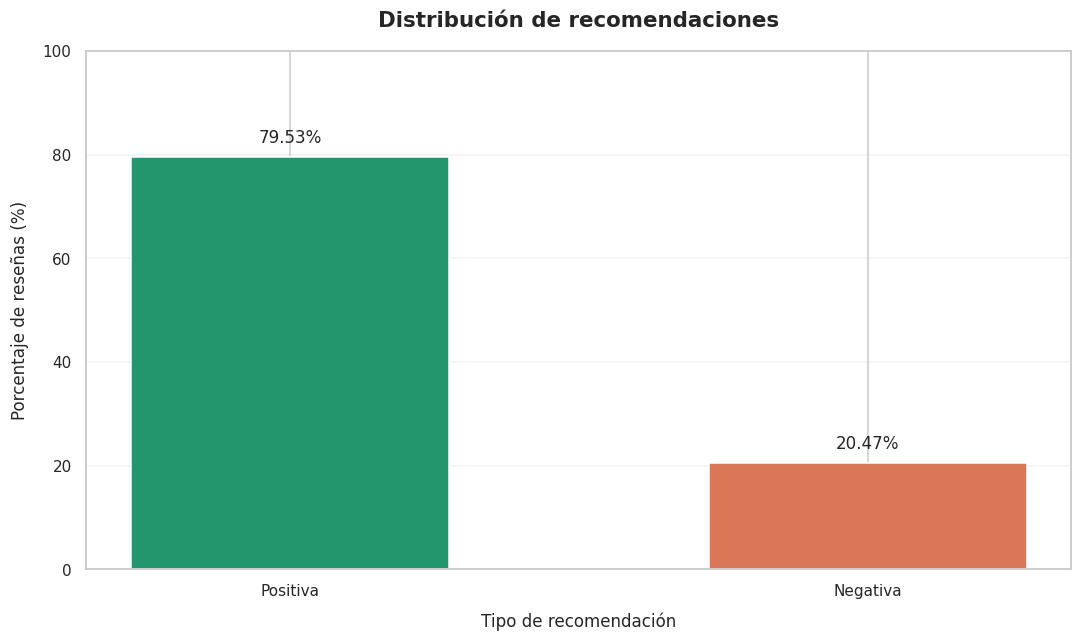

[OK] 01_distribucion_recomendaciones.png


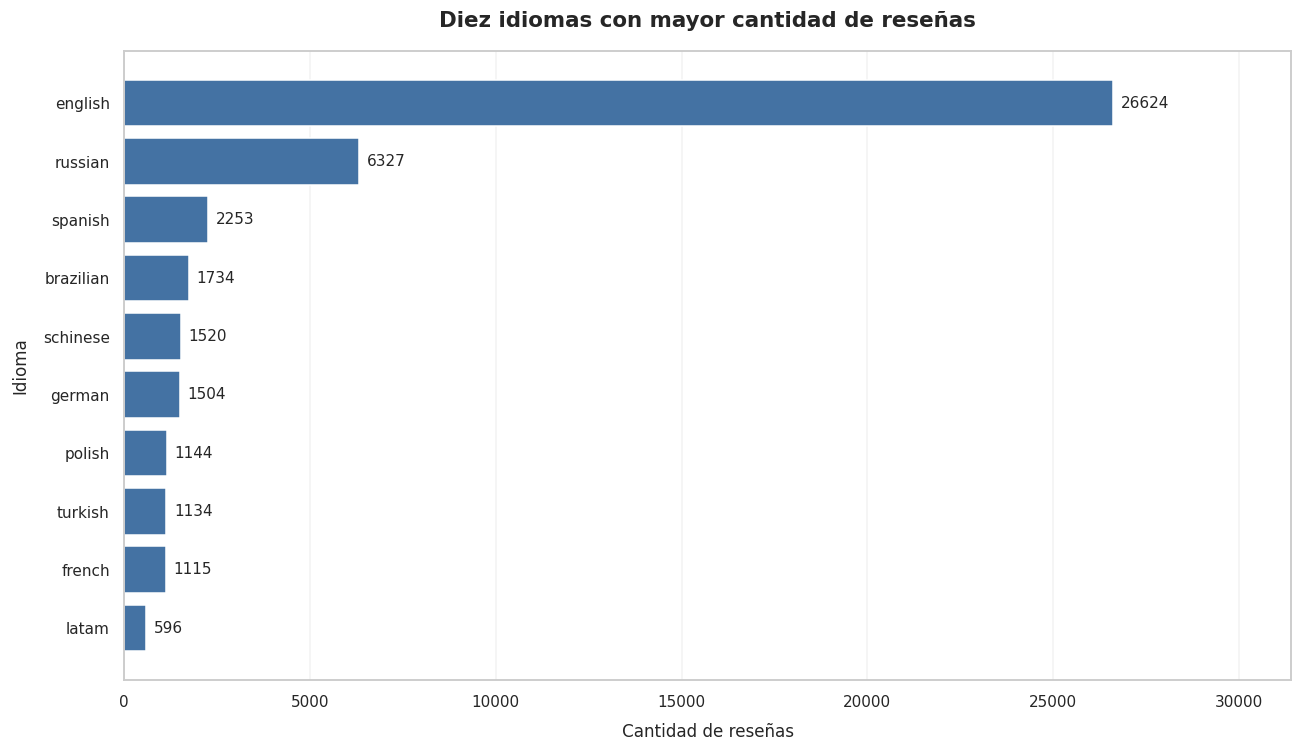

[OK] 02_distribucion_idiomas.png


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


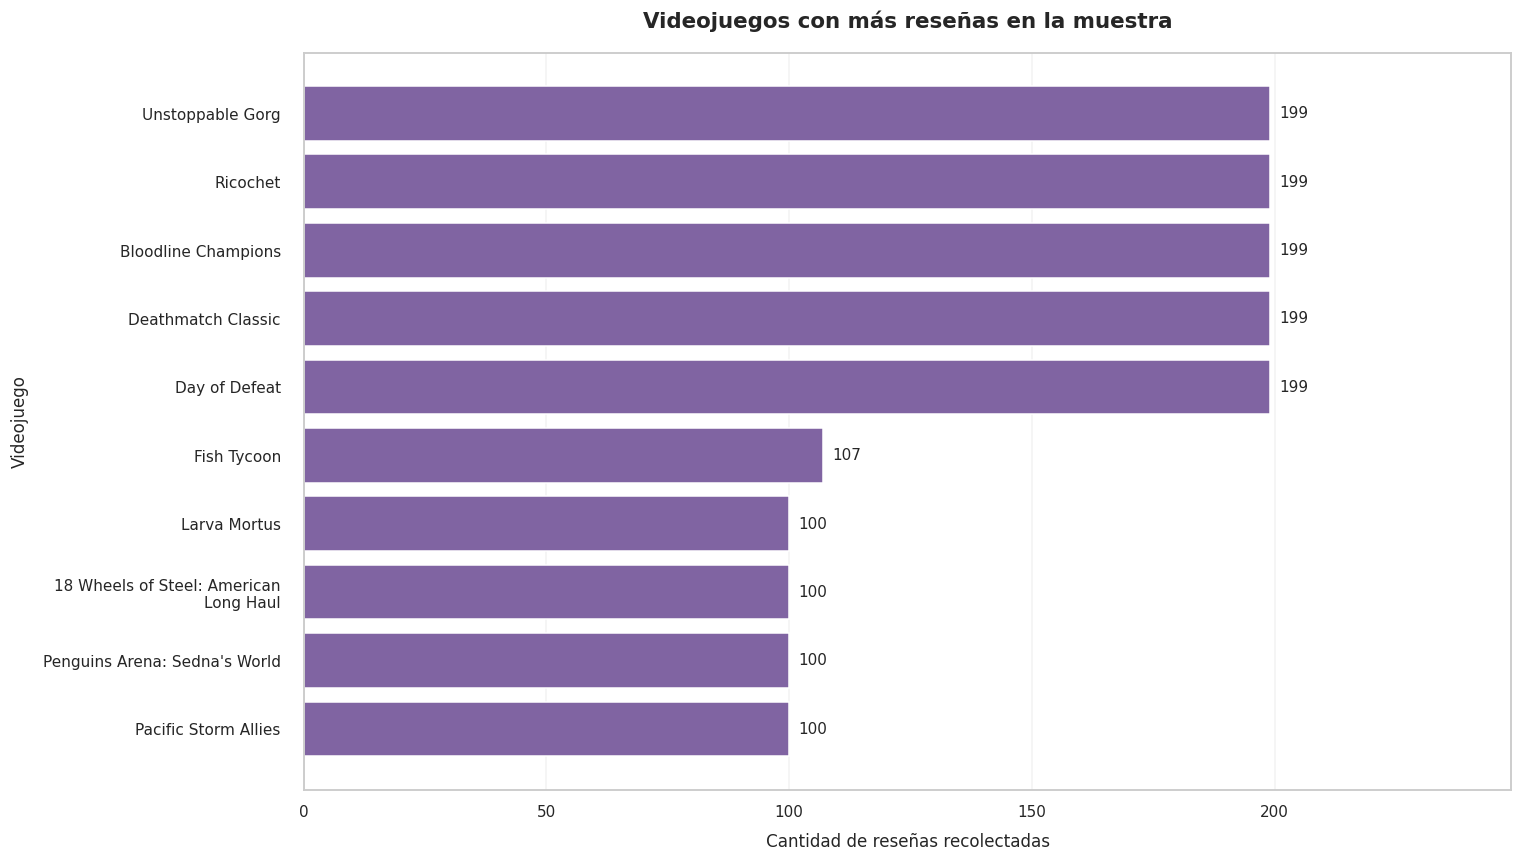

[OK] 03_top_juegos_resenas.png


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


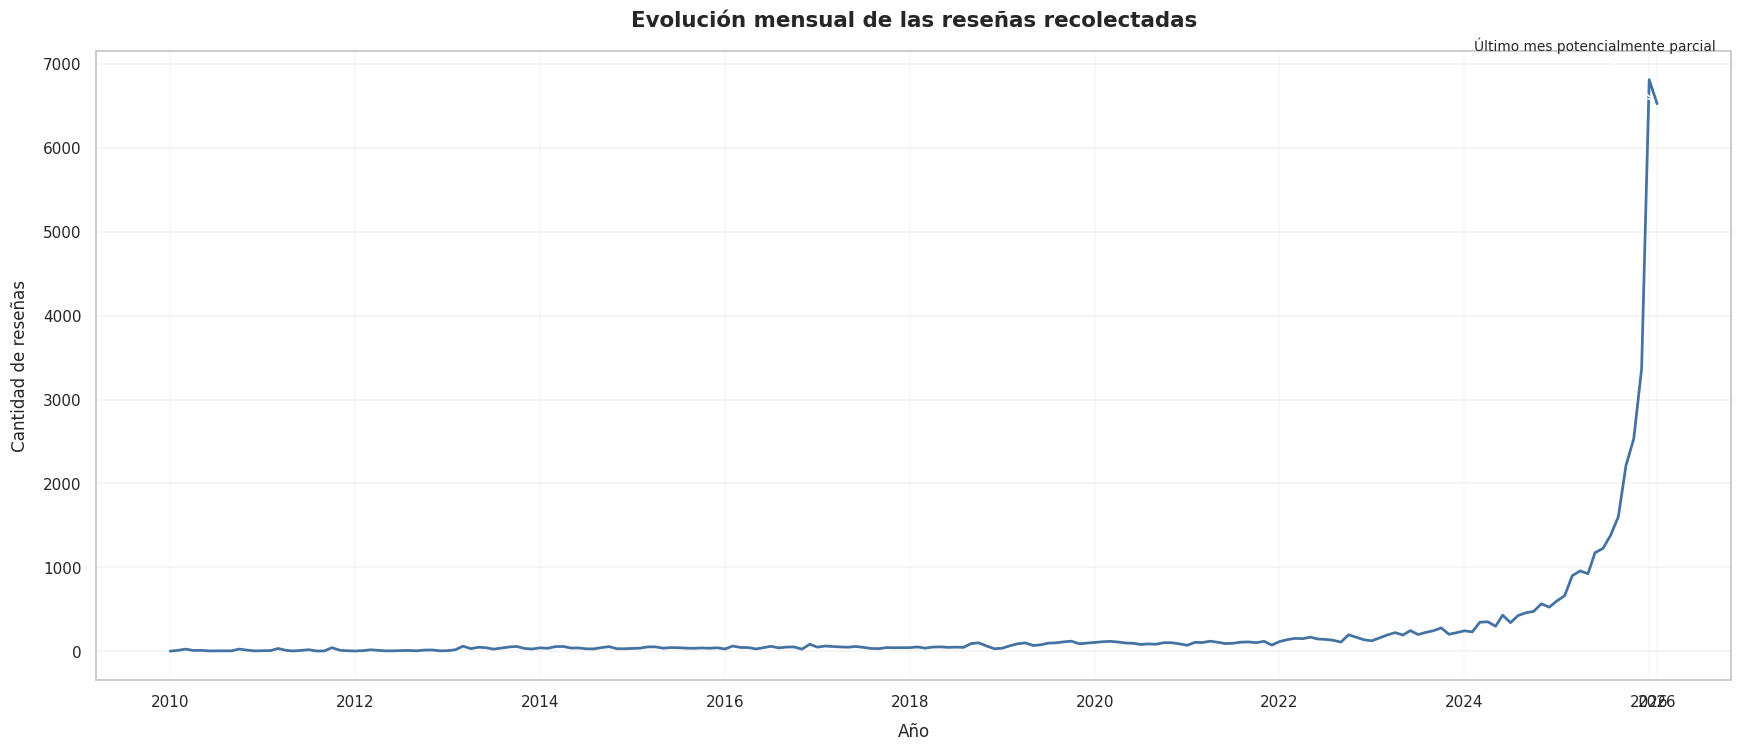

[OK] 04_evolucion_mensual.png


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


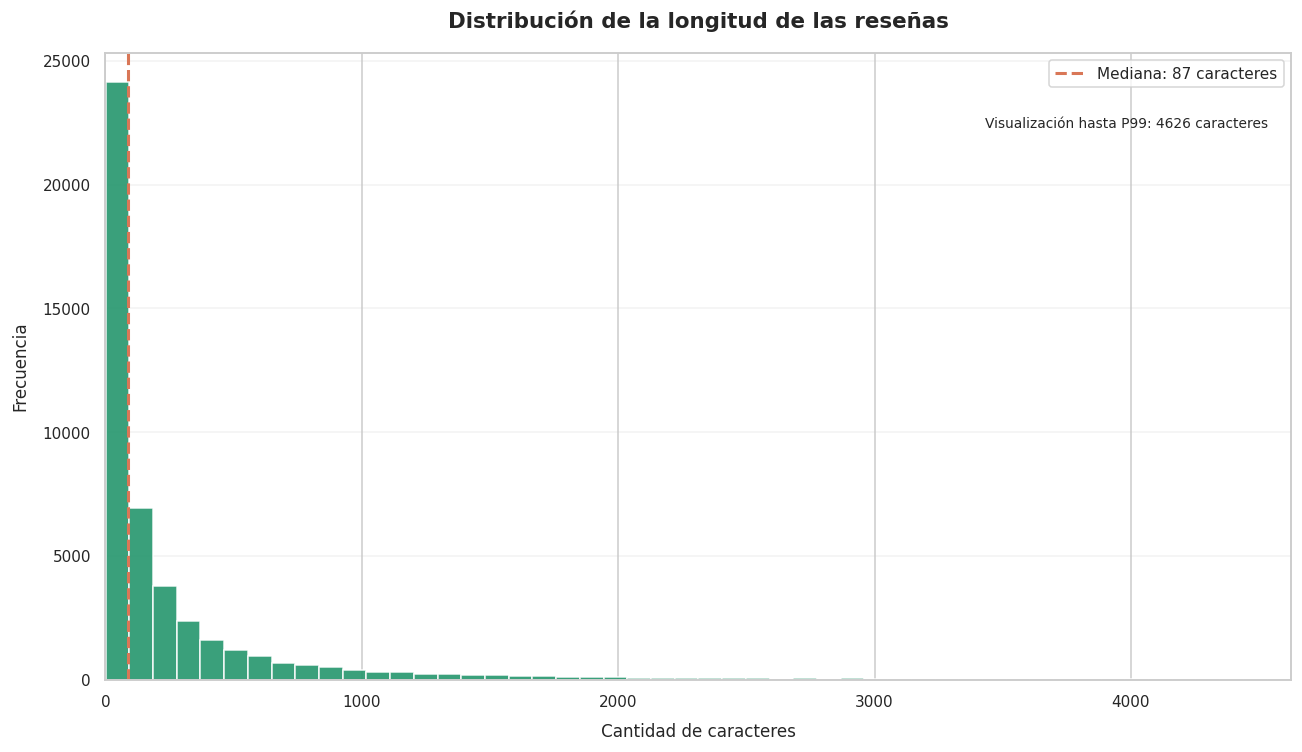

[OK] 05_longitud_resenas.png


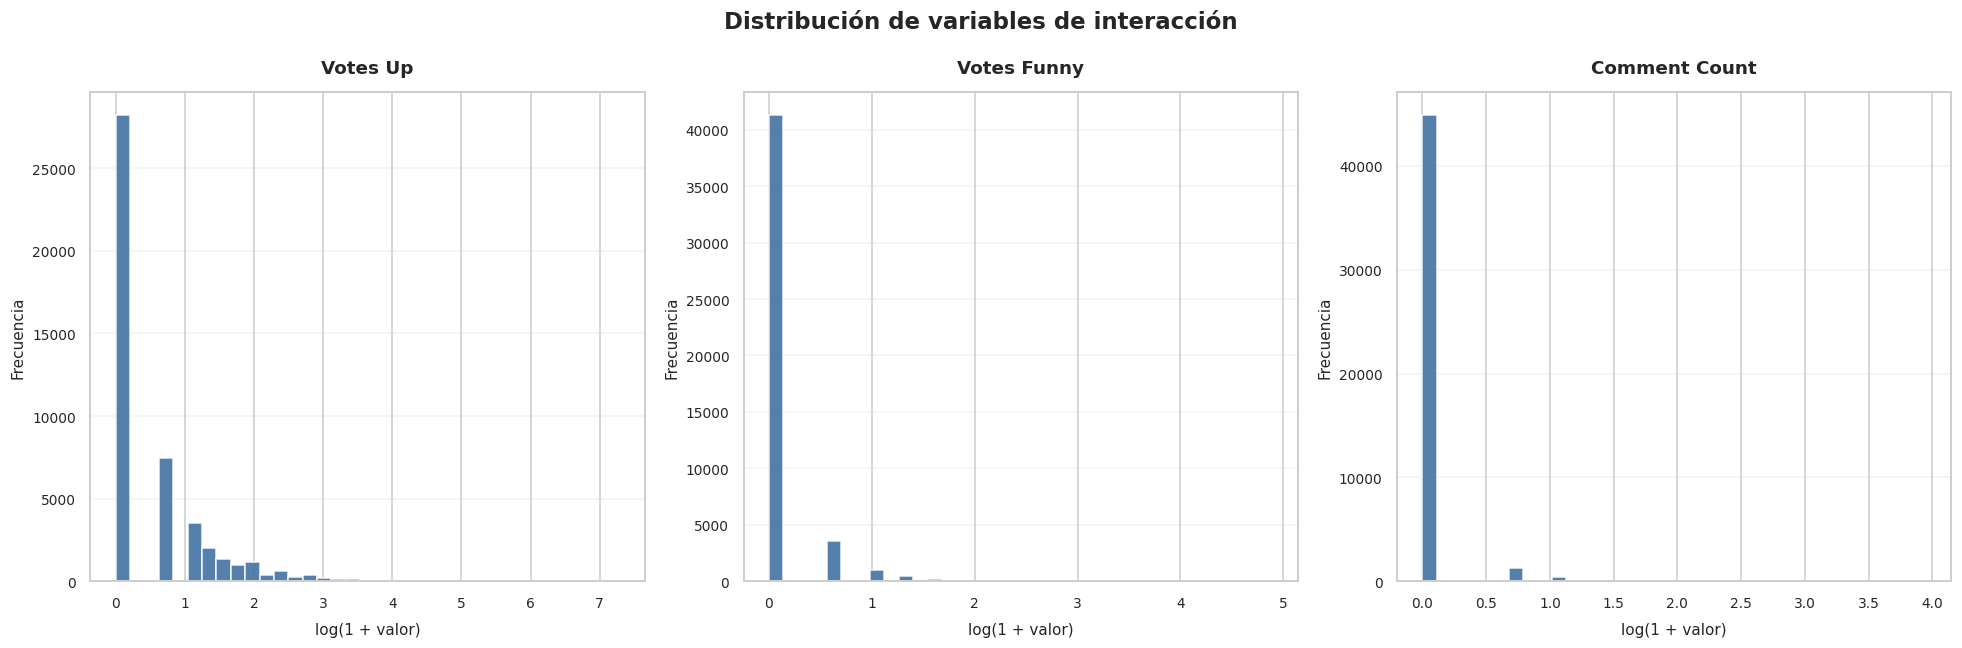

[OK] 06_distribucion_interaccion.png


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


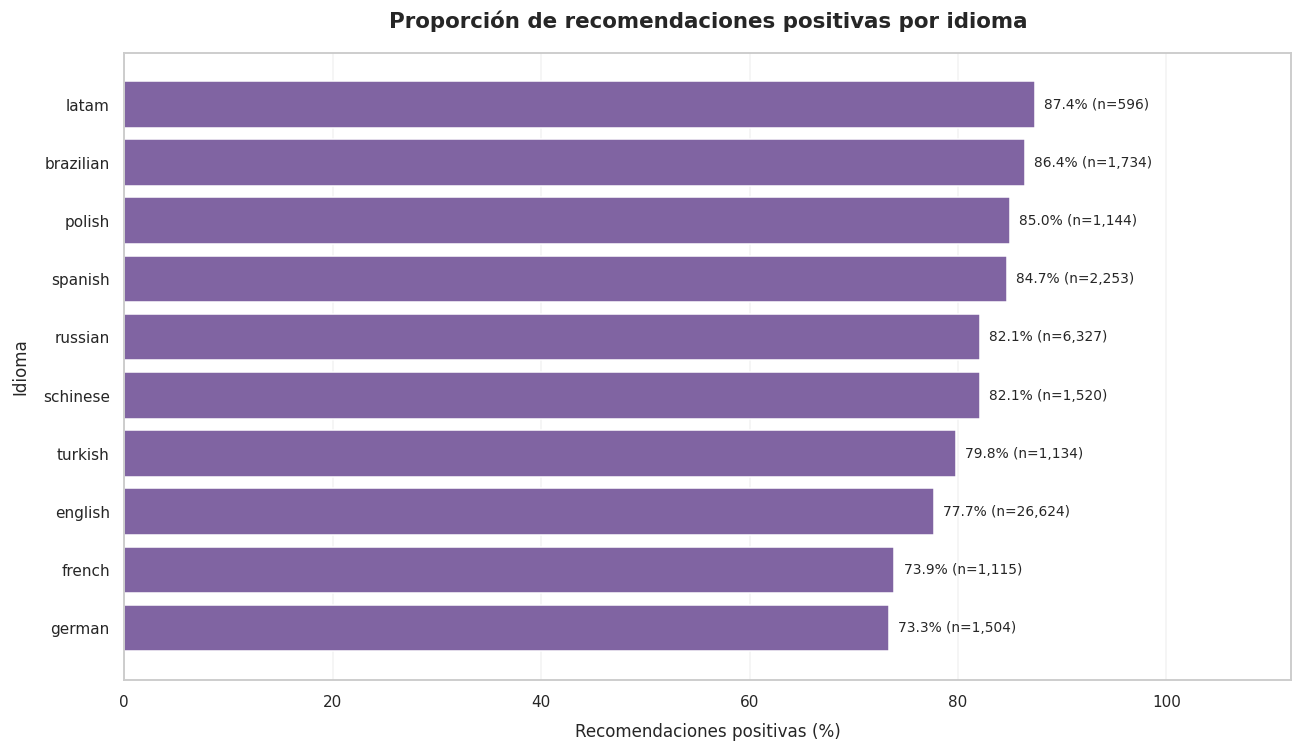

[OK] 07_recomendaciones_positivas_idioma.png

RESUMEN DE VISUALIZACIONES
[OK] 01_distribucion_recomendaciones.png
[OK] 02_distribucion_idiomas.png
[OK] 03_top_juegos_resenas.png
[OK] 04_evolucion_mensual.png
[OK] 05_longitud_resenas.png
[OK] 06_distribucion_interaccion.png
[OK] 07_recomendaciones_positivas_idioma.png

Total de gráficos: 7
Directorio: /content/drive/MyDrive/Infraestructura-de-ciencia-de-datos/Analytics/Visualizations/EDA_Estadistica

VISUALIZACIONES ACTUALIZADAS CORRECTAMENTE


In [9]:

# ============================================================
# STEAM ANALYTICS
# NOTEBOOK 1 - CELDA 6
# VISUALIZACIONES EXPLORATORIAS - FORMATO MEJORADO
# ============================================================

print("=" * 85)
print("ANÁLISIS EXPLORATORIO - VISUALIZACIONES")
print("=" * 85)

# ------------------------------------------------------------
# 1. CONFIGURACIÓN GENERAL
# ------------------------------------------------------------

VISUALIZATIONS.mkdir(parents=True, exist_ok=True)

def guardar_figura(fig, nombre):
    fig.tight_layout()
    ruta = VISUALIZATIONS / nombre
    fig.savefig(
        ruta,
        dpi=180,
        bbox_inches="tight",
        facecolor="white"
    )
    plt.show()
    plt.close(fig)
    print(f"[OK] {nombre}")


def configurar_ejes(ax, titulo, xlabel, ylabel):
    ax.set_title(titulo, fontsize=14, fontweight="bold", pad=16)
    ax.set_xlabel(xlabel, fontsize=11, labelpad=9)
    ax.set_ylabel(ylabel, fontsize=11, labelpad=9)
    ax.tick_params(axis="both", labelsize=10)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)


# ------------------------------------------------------------
# 2. DISTRIBUCIÓN DE RECOMENDACIONES
# ------------------------------------------------------------

conteo = (
    df_resenas["voted_up"]
    .map({True: "Positiva", False: "Negativa"})
    .value_counts()
    .reindex(["Positiva", "Negativa"], fill_value=0)
)

porcentaje = conteo / conteo.sum() * 100

fig, ax = plt.subplots(figsize=(10, 6))

barras = ax.bar(
    conteo.index,
    porcentaje.values,
    width=0.55,
    color=["#24966D", "#D97757"]
)

ax.bar_label(
    barras,
    labels=[f"{v:.2f}%" for v in porcentaje],
    fontsize=11,
    padding=7
)

configurar_ejes(
    ax,
    "Distribución de recomendaciones",
    "Tipo de recomendación",
    "Porcentaje de reseñas (%)"
)

ax.set_ylim(0, 100)

guardar_figura(
    fig,
    "01_distribucion_recomendaciones.png"
)


# ------------------------------------------------------------
# 3. DISTRIBUCIÓN POR IDIOMA
# ------------------------------------------------------------

idiomas_plot = (
    distribucion_idiomas[
        distribucion_idiomas["language_code"] != "UNKNOWN"
    ]
    .head(10)
    .sort_values("cantidad_resenas")
    .copy()
)

fig, ax = plt.subplots(figsize=(12, 7))

barras = ax.barh(
    idiomas_plot["language_code"],
    idiomas_plot["cantidad_resenas"],
    color="#4472A3"
)

ax.bar_label(
    barras,
    padding=5,
    fontsize=10,
    fmt="%.0f"
)

configurar_ejes(
    ax,
    "Diez idiomas con mayor cantidad de reseñas",
    "Cantidad de reseñas",
    "Idioma"
)

ax.set_xlim(
    0,
    idiomas_plot["cantidad_resenas"].max() * 1.18
)

ax.grid(axis="x", alpha=0.25)
ax.grid(axis="y", visible=False)

guardar_figura(
    fig,
    "02_distribucion_idiomas.png"
)


# ------------------------------------------------------------
# 4. VIDEOJUEGOS CON MÁS RESEÑAS
# ------------------------------------------------------------

top_juegos = (
    resenas_por_juego
    .head(10)
    .sort_values("cantidad_resenas")
    .copy()
)

fig, ax = plt.subplots(figsize=(14, 8))

# Ajustar automáticamente nombres extensos
nombres = (
    top_juegos["name"]
    .fillna("Juego desconocido")
    .astype(str)
    .str.wrap(32)
)

posiciones = np.arange(len(top_juegos))

barras = ax.barh(
    posiciones,
    top_juegos["cantidad_resenas"],
    color="#8064A2"
)

ax.set_yticks(posiciones)
ax.set_yticklabels(nombres, fontsize=10)

ax.bar_label(
    barras,
    padding=6,
    fontsize=10,
    fmt="%.0f"
)

configurar_ejes(
    ax,
    "Videojuegos con más reseñas en la muestra",
    "Cantidad de reseñas recolectadas",
    "Videojuego"
)

ax.tick_params(axis="y", pad=9)

ax.set_xlim(
    0,
    top_juegos["cantidad_resenas"].max() * 1.25
)

ax.grid(axis="x", alpha=0.25)
ax.grid(axis="y", visible=False)

guardar_figura(
    fig,
    "03_top_juegos_resenas.png"
)


# ------------------------------------------------------------
# 5. EVOLUCIÓN MENSUAL DE RESEÑAS
# ------------------------------------------------------------

mensual = actividad_mensual.copy()

fechas_plot = pd.to_datetime(
    mensual["periodo"].astype(str) + "-01",
    errors="coerce"
)

mensual["fecha_grafico"] = fechas_plot

mensual = mensual.dropna(
    subset=["fecha_grafico"]
).sort_values("fecha_grafico")

fig, ax = plt.subplots(figsize=(16, 7))

ax.plot(
    mensual["fecha_grafico"],
    mensual["cantidad_resenas"],
    linewidth=1.8,
    color="#4472A3"
)

configurar_ejes(
    ax,
    "Evolución mensual de las reseñas recolectadas",
    "Año",
    "Cantidad de reseñas"
)

# Mostrar una etiqueta cada dos años para evitar superposición
indices = list(range(0, len(mensual), 24))

if len(mensual) - 1 not in indices:
    indices.append(len(mensual) - 1)

ax.set_xticks(
    mensual["fecha_grafico"].iloc[indices]
)

ax.set_xticklabels(
    mensual["fecha_grafico"]
    .iloc[indices]
    .dt.strftime("%Y"),
    fontsize=10
)

ax.grid(axis="x", alpha=0.15)

# Identificar el último mes como posiblemente parcial
ultima_fecha = df_resenas[
    "timestamp_created_parsed"
].max()

if pd.notna(ultima_fecha):

    # Eliminar zona horaria antes de comparar períodos
    ultima_fecha_naive = ultima_fecha.tz_convert(None)

    ultimo_periodo = ultima_fecha_naive.to_period("M")

    periodo_final = pd.Period(
        mensual["periodo"].iloc[-1],
        freq="M"
    )

    if ultimo_periodo == periodo_final:

        x_final = mensual["fecha_grafico"].iloc[-1]
        y_final = mensual["cantidad_resenas"].iloc[-1]

        ax.annotate(
            "Último mes potencialmente parcial",
            xy=(x_final, y_final),
            xytext=(-120, 35),
            textcoords="offset points",
            arrowprops={"arrowstyle": "->"},
            fontsize=9
        )

guardar_figura(
    fig,
    "04_evolucion_mensual.png"
)


# ------------------------------------------------------------
# 6. DISTRIBUCIÓN DE LONGITUD DE RESEÑAS
# ------------------------------------------------------------

longitudes = (
    df_resenas["review"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.len()
)

longitudes = longitudes[longitudes > 0]

p99 = longitudes.quantile(0.99)

longitudes_visibles = longitudes[
    longitudes <= p99
]

fig, ax = plt.subplots(figsize=(12, 7))

ax.hist(
    longitudes_visibles,
    bins=50,
    color="#24966D",
    edgecolor="white",
    alpha=0.9
)

ax.axvline(
    longitudes.median(),
    color="#D97757",
    linestyle="--",
    linewidth=2,
    label=f"Mediana: {longitudes.median():.0f} caracteres"
)

configurar_ejes(
    ax,
    "Distribución de la longitud de las reseñas",
    "Cantidad de caracteres",
    "Frecuencia"
)

ax.set_xlim(0, p99)

ax.legend(
    fontsize=10,
    loc="upper right"
)

ax.text(
    0.98,
    0.88,
    f"Visualización hasta P99: {p99:.0f} caracteres",
    transform=ax.transAxes,
    ha="right",
    fontsize=9
)

guardar_figura(
    fig,
    "05_longitud_resenas.png"
)


# ------------------------------------------------------------
# 7. DISTRIBUCIÓN DE VARIABLES DE INTERACCIÓN
# ------------------------------------------------------------

variables = [
    "votes_up",
    "votes_funny",
    "comment_count"
]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6)
)

for ax, columna in zip(axes, variables):

    valores = pd.to_numeric(
        df_resenas[columna],
        errors="coerce"
    ).dropna()

    valores = valores[valores >= 0]

    transformados = np.log1p(valores)

    ax.hist(
        transformados,
        bins=35,
        color="#4472A3",
        edgecolor="white",
        alpha=0.9
    )

    ax.set_title(
        columna.replace("_", " ").title(),
        fontsize=12,
        fontweight="bold",
        pad=12
    )

    ax.set_xlabel(
        "log(1 + valor)",
        fontsize=10,
        labelpad=8
    )

    ax.set_ylabel(
        "Frecuencia",
        fontsize=10
    )

    ax.tick_params(labelsize=9)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

fig.suptitle(
    "Distribución de variables de interacción",
    fontsize=15,
    fontweight="bold"
)

guardar_figura(
    fig,
    "06_distribucion_interaccion.png"
)


# ------------------------------------------------------------
# 8. RECOMENDACIONES POSITIVAS POR IDIOMA
# ------------------------------------------------------------

idioma_recomendaciones = df_resenas[
    ["language_key", "voted_up"]
].merge(
    df_idiomas[["language_key", "language_code"]],
    on="language_key",
    how="left",
    validate="many_to_one"
)

idioma_recomendaciones = idioma_recomendaciones[
    idioma_recomendaciones["language_code"].notna() &
    (idioma_recomendaciones["language_code"] != "UNKNOWN") &
    idioma_recomendaciones["voted_up"].notna()
]

tasas_idioma = (
    idioma_recomendaciones
    .groupby("language_code")
    .agg(
        cantidad=("voted_up", "size"),
        tasa_positiva=("voted_up", "mean")
    )
    .reset_index()
)

# Exigir un mínimo de 100 reseñas por idioma
tasas_idioma = tasas_idioma[
    tasas_idioma["cantidad"] >= 100
].sort_values(
    "cantidad",
    ascending=False
).head(10)

tasas_idioma = tasas_idioma.sort_values(
    "tasa_positiva"
)

fig, ax = plt.subplots(figsize=(12, 7))

barras = ax.barh(
    tasas_idioma["language_code"],
    tasas_idioma["tasa_positiva"] * 100,
    color="#8064A2"
)

etiquetas = [
    f"{valor:.1f}% (n={cantidad:,})"
    for valor, cantidad in zip(
        tasas_idioma["tasa_positiva"] * 100,
        tasas_idioma["cantidad"]
    )
]

ax.bar_label(
    barras,
    labels=etiquetas,
    padding=6,
    fontsize=9
)

configurar_ejes(
    ax,
    "Proporción de recomendaciones positivas por idioma",
    "Recomendaciones positivas (%)",
    "Idioma"
)

ax.set_xlim(0, 112)

ax.grid(axis="x", alpha=0.25)
ax.grid(axis="y", visible=False)

guardar_figura(
    fig,
    "07_recomendaciones_positivas_idioma.png"
)


# ------------------------------------------------------------
# 9. RESUMEN FINAL
# ------------------------------------------------------------

archivos_generados = sorted(
    VISUALIZATIONS.glob("*.png")
)

print("\n" + "=" * 85)
print("RESUMEN DE VISUALIZACIONES")
print("=" * 85)

for archivo in archivos_generados:
    print(f"[OK] {archivo.name}")

print(f"\nTotal de gráficos: {len(archivos_generados)}")
print(f"Directorio: {VISUALIZATIONS}")

print("\nVISUALIZACIONES ACTUALIZADAS CORRECTAMENTE")



## 8. Análisis estadístico y contraste de hipótesis

### 8.1. Objetivo

Investigar relaciones entre las características de las reseñas y el comportamiento de los usuarios mediante técnicas de estadística inferencial.

Se buscará determinar si las diferencias observadas durante el análisis exploratorio cuentan con evidencia estadística y evaluar la magnitud de las asociaciones identificadas.

### 8.2. Unidad de análisis

Para reducir la dependencia generada por usuarios que publicaron varias reseñas, los primeros contrastes utilizarán una observación por usuario: su reseña más reciente dentro de la muestra.

Esta decisión reduce la repetición de observaciones por usuario, aunque no elimina todos los posibles agrupamientos por videojuego.

### 8.3. Hipótesis 1 — Tiempo de juego y recomendación

**Pregunta:** ¿Las distribuciones del tiempo de juego al momento de publicar una reseña son diferentes entre las recomendaciones positivas y negativas?

- H0: ambas distribuciones son iguales.
- H1: las distribuciones son diferentes.

Método: prueba U de Mann-Whitney.

Se informarán los tamaños de muestra, medianas, rangos intercuartílicos, valor p y tamaño de efecto mediante correlación biserial de rangos.

### 8.4. Hipótesis 2 — Idioma y recomendación

**Pregunta:** ¿Existe una asociación entre el idioma de la reseña y el resultado de la recomendación?

- H0: el idioma y la recomendación son independientes.
- H1: existe una asociación entre ambas variables.

Método: prueba chi-cuadrado de independencia.

Se utilizará V de Cramér para medir la magnitud de la asociación.

Se considerarán las categorías con menos de 100 observaciones dentro de un grupo denominado "Otros", evitando interpretar grupos con muestras demasiado pequeñas de manera individual.

### 8.5. Criterios estadísticos

- Nivel de significación: 0,05.
- Corrección de Bonferroni para los contrastes realizados.
- Se informarán tamaños de efecto además de valores p.
- Se comprobarán las condiciones de aplicación de las pruebas.
- Los resultados se interpretarán como asociaciones exploratorias y no como relaciones causales.

### 8.6. Limitaciones

La muestra no es una selección aleatoria de todas las reseñas de Steam.

La selección de la reseña más reciente por usuario reduce la repetición de usuarios, pero puede existir dependencia entre observaciones correspondientes a un mismo videojuego.

Las conclusiones no se generalizarán automáticamente a toda la plataforma.

### 8.7. Resultados esperados

- Tabla de resultados de hipótesis.
- Estadísticos de las pruebas.
- Valores p ajustados.
- Tamaños de efecto.
- Tablas de contingencia.
- Interpretación y conclusiones estadísticas.

Los resultados se almacenarán en `Analytics/Reports/EDA_Estadistica/`.


In [11]:

# ============================================================
# STEAM ANALYTICS
# NOTEBOOK 1 - CELDA 7
# CONTRASTE DE HIPÓTESIS ESTADÍSTICAS
# ============================================================

print("=" * 85)
print("ANÁLISIS ESTADÍSTICO - CONTRASTE DE HIPÓTESIS")
print("=" * 85)

# ------------------------------------------------------------
# 1. PREPARACIÓN DE LA MUESTRA INFERENCIAL
# ------------------------------------------------------------

columnas = [
    "recommendationid",
    "user_key",
    "game_key",
    "language_key",
    "voted_up",
    "timestamp_created_parsed",
    "author.playtime_at_review"
]

muestra = df_resenas[columnas].copy()

muestra["fecha"] = pd.to_datetime(
    muestra["timestamp_created_parsed"],
    errors="coerce",
    utc=True
)

muestra["user_key"] = pd.to_numeric(
    muestra["user_key"],
    errors="coerce"
)

muestra["playtime_minutos"] = pd.to_numeric(
    muestra["author.playtime_at_review"],
    errors="coerce"
)

# Excluir usuario desconocido y fechas inválidas
muestra = muestra[
    (muestra["user_key"] > 0) &
    muestra["fecha"].notna() &
    muestra["voted_up"].notna()
].copy()

# Una observación por usuario:
# se conserva su reseña más reciente en la muestra.
muestra = (
    muestra.sort_values(
        ["fecha", "recommendationid"]
    )
    .drop_duplicates(
        subset="user_key",
        keep="last"
    )
    .copy()
)

print("\n1. MUESTRA INFERENCIAL")
print(f"Reseñas originales: {len(df_resenas):,}")
print(f"Usuarios representados: {len(muestra):,}")
print(
    "Usuarios únicos: "
    f"{muestra['user_key'].nunique():,}"
)

# ------------------------------------------------------------
# 2. PREPARAR RESULTADOS DE CONTRASTES
# ------------------------------------------------------------

resultados = []
p_values = []

# ------------------------------------------------------------
# 3. HIPÓTESIS 1:
# TIEMPO DE JUEGO Y RECOMENDACIÓN
# ------------------------------------------------------------

print("\n" + "-" * 75)
print("HIPÓTESIS 1: TIEMPO DE JUEGO Y RECOMENDACIÓN")
print("-" * 75)

h1 = muestra[
    muestra["playtime_minutos"].notna() &
    (muestra["playtime_minutos"] >= 0)
].copy()

positivas = h1.loc[
    h1["voted_up"] == True,
    "playtime_minutos"
].to_numpy()

negativas = h1.loc[
    h1["voted_up"] == False,
    "playtime_minutos"
].to_numpy()

if len(positivas) >= 2 and len(negativas) >= 2:

    prueba_h1 = stats.mannwhitneyu(
        positivas,
        negativas,
        alternative="two-sided",
        method="auto"
    )

    n_pos = len(positivas)
    n_neg = len(negativas)

    # Tamaño de efecto: correlación biserial de rangos.
    efecto_h1 = (
        2 * prueba_h1.statistic / (n_pos * n_neg)
    ) - 1

    mediana_pos = np.median(positivas)
    mediana_neg = np.median(negativas)

    q1_pos, q3_pos = np.percentile(
        positivas, [25, 75]
    )

    q1_neg, q3_neg = np.percentile(
        negativas, [25, 75]
    )

    p_h1 = float(prueba_h1.pvalue)
    p_values.append(p_h1)

    resultados.append({
        "hipotesis": "H1",
        "pregunta": "Tiempo de juego y recomendación",
        "metodo": "Mann-Whitney U",
        "n": n_pos + n_neg,
        "grupo_1": "Positivas",
        "n_grupo_1": n_pos,
        "mediana_grupo_1": mediana_pos,
        "q1_grupo_1": q1_pos,
        "q3_grupo_1": q3_pos,
        "grupo_2": "Negativas",
        "n_grupo_2": n_neg,
        "mediana_grupo_2": mediana_neg,
        "q1_grupo_2": q1_neg,
        "q3_grupo_2": q3_neg,
        "estadistico": float(prueba_h1.statistic),
        "p_valor": p_h1,
        "tamano_efecto": efecto_h1,
        "significado_efecto": "Correlación biserial de rangos"
    })

    print(f"Reseñas positivas: {n_pos:,}")
    print(f"Reseñas negativas: {n_neg:,}")
    print(f"Mediana positivas: {mediana_pos:.2f} minutos")
    print(f"Mediana negativas: {mediana_neg:.2f} minutos")
    print(f"Estadístico U: {prueba_h1.statistic:.2f}")
    print(f"Valor p: {p_h1:.8g}")
    print(f"Correlación biserial: {efecto_h1:.4f}")

else:
    print("No hay suficientes observaciones para realizar H1.")

# ------------------------------------------------------------
# 4. HIPÓTESIS 2:
# IDIOMA Y RECOMENDACIÓN
# ------------------------------------------------------------

print("\n" + "-" * 75)
print("HIPÓTESIS 2: IDIOMA Y RECOMENDACIÓN")
print("-" * 75)

idioma_base = muestra[
    ["language_key", "voted_up"]
].copy()

idioma_base = idioma_base.merge(
    df_idiomas[["language_key", "language_code"]],
    on="language_key",
    how="left",
    validate="many_to_one"
)

# Excluir idioma desconocido.
idioma_base = idioma_base[
    idioma_base["language_code"].notna() &
    (idioma_base["language_key"] != 0) &
    (idioma_base["language_code"] != "UNKNOWN")
].copy()

conteos = idioma_base["language_code"].value_counts()

idiomas_grandes = conteos[
    conteos >= 100
].index

idioma_base["idioma_analisis"] = np.where(
    idioma_base["language_code"].isin(idiomas_grandes),
    idioma_base["language_code"],
    "Otros (<100)"
)

# Tabla de contingencia
tabla_idioma = pd.crosstab(
    idioma_base["idioma_analisis"],
    idioma_base["voted_up"]
)

tabla_idioma = tabla_idioma.reindex(
    columns=[False, True],
    fill_value=0
)

tabla_idioma = tabla_idioma.rename(
    columns={
        False: "Negativa",
        True: "Positiva"
    }
)

# Ejecutar la prueba si existen grupos suficientes.
if (
    tabla_idioma.shape[0] >= 2 and
    tabla_idioma.shape[1] == 2 and
    (tabla_idioma.sum(axis=0) > 0).all()
):

    chi2, p_h2, grados, esperados = stats.chi2_contingency(
        tabla_idioma,
        correction=False
    )

    n_h2 = tabla_idioma.to_numpy().sum()

    # V de Cramér
    minimo_dim = min(
        tabla_idioma.shape[0] - 1,
        tabla_idioma.shape[1] - 1
    )

    cramers_v = np.sqrt(
        chi2 / (n_h2 * minimo_dim)
    )

    esperado_minimo = esperados.min()

    p_h2 = float(p_h2)
    p_values.append(p_h2)

    resultados.append({
        "hipotesis": "H2",
        "pregunta": "Idioma y recomendación",
        "metodo": "Chi-cuadrado de independencia",
        "n": int(n_h2),
        "grupo_1": "Idiomas",
        "n_grupo_1": tabla_idioma.shape[0],
        "mediana_grupo_1": np.nan,
        "q1_grupo_1": np.nan,
        "q3_grupo_1": np.nan,
        "grupo_2": "Recomendaciones",
        "n_grupo_2": 2,
        "mediana_grupo_2": np.nan,
        "q1_grupo_2": np.nan,
        "q3_grupo_2": np.nan,
        "estadistico": float(chi2),
        "p_valor": p_h2,
        "tamano_efecto": float(cramers_v),
        "significado_efecto": "V de Cramér"
    })

    print("\nTABLA DE CONTINGENCIA")
    display(tabla_idioma)

    print(f"Observaciones: {n_h2:,}")
    print(f"Grados de libertad: {grados}")
    print(f"Chi-cuadrado: {chi2:.4f}")
    print(f"Valor p: {p_h2:.8g}")
    print(f"V de Cramér: {cramers_v:.4f}")
    print(f"Frecuencia esperada mínima: {esperado_minimo:.2f}")

    if esperado_minimo < 5:
        print(
            "ADVERTENCIA: existen frecuencias esperadas inferiores a 5. "
            "La aproximación chi-cuadrado puede no ser adecuada."
        )

else:
    print("No hay suficientes categorías para realizar H2.")

# ------------------------------------------------------------
# 5. CORRECCIÓN POR COMPARACIONES MÚLTIPLES
# ------------------------------------------------------------

df_resultados = pd.DataFrame(resultados)

if not df_resultados.empty:

    cantidad_pruebas = len(p_values)

    df_resultados["p_ajustado_bonferroni"] = [
        min(p * cantidad_pruebas, 1.0)
        for p in p_values
    ]

    df_resultados["alpha"] = 0.05

    df_resultados["decision_estadistica"] = np.where(
        df_resultados["p_ajustado_bonferroni"] < 0.05,
        "Rechazar H0",
        "No rechazar H0"
    )

    df_resultados["interpretacion"] = np.where(
        df_resultados["p_ajustado_bonferroni"] < 0.05,
        "Se encontró evidencia estadística de diferencia o asociación.",
        "No se encontró evidencia estadística suficiente."
    )

# ------------------------------------------------------------
# 6. PRESENTACIÓN
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("RESULTADOS DE CONTRASTE DE HIPÓTESIS")
print("=" * 85)

if not df_resultados.empty:

    display(
        df_resultados[
            [
                "hipotesis",
                "metodo",
                "n",
                "estadistico",
                "p_valor",
                "p_ajustado_bonferroni",
                "tamano_efecto",
                "decision_estadistica"
            ]
        ]
    )

else:
    print("No se pudieron ejecutar los contrastes.")

# ------------------------------------------------------------
# 7. EXPORTACIONES
# ------------------------------------------------------------

if not df_resultados.empty:

    df_resultados.to_csv(
        REPORTS / "resultados_contraste_hipotesis.csv",
        index=False,
        encoding="utf-8-sig"
    )

    tabla_idioma.to_csv(
        REPORTS / "tabla_contingencia_idioma.csv",
        encoding="utf-8-sig"
    )

print("\nINFORMES GUARDADOS EN:")
print(REPORTS)

print("\nCONTRASTES ESTADÍSTICOS FINALIZADOS")


ANÁLISIS ESTADÍSTICO - CONTRASTE DE HIPÓTESIS


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



1. MUESTRA INFERENCIAL
Reseñas originales: 46,990
Usuarios representados: 38,999
Usuarios únicos: 38,999

---------------------------------------------------------------------------
HIPÓTESIS 1: TIEMPO DE JUEGO Y RECOMENDACIÓN
---------------------------------------------------------------------------
Reseñas positivas: 31,415
Reseñas negativas: 7,531
Mediana positivas: 528.00 minutos
Mediana negativas: 170.00 minutos
Estadístico U: 162227268.00
Valor p: 0
Correlación biserial: 0.3714

---------------------------------------------------------------------------
HIPÓTESIS 2: IDIOMA Y RECOMENDACIÓN
---------------------------------------------------------------------------

TABLA DE CONTINGENCIA


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


voted_up,Negativa,Positiva
idioma_analisis,,
Otros (<100),72,449
brazilian,186,1273
czech,42,273
dutch,27,110
english,4642,17603
french,253,697
german,346,945
hungarian,24,118
italian,72,323


Observaciones: 38,999
Grados de libertad: 19
Chi-cuadrado: 278.2935
Valor p: 5.4878069e-48
V de Cramér: 0.0845
Frecuencia esperada mínima: 19.55

RESULTADOS DE CONTRASTE DE HIPÓTESIS


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,hipotesis,metodo,n,estadistico,p_valor,p_ajustado_bonferroni,tamano_efecto,decision_estadistica
0,H1,Mann-Whitney U,38946,"162,227,268.000",0.000,0.000,0.371,Rechazar H0
1,H2,Chi-cuadrado de independencia,38999,278.294,0.000,0.000,0.084,Rechazar H0



INFORMES GUARDADOS EN:
/content/drive/MyDrive/Infraestructura-de-ciencia-de-datos/Analytics/Reports/EDA_Estadistica

CONTRASTES ESTADÍSTICOS FINALIZADOS


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



## 8.8. Resultados e interpretación de los contrastes estadísticos

### Hipótesis 1 — Tiempo de juego y recomendación

La prueba U de Mann-Whitney permitió identificar diferencias estadísticamente significativas entre las distribuciones de tiempo de juego de las reseñas positivas y negativas.

Los resultados fueron:

- Reseñas positivas: 31.415 observaciones.
- Reseñas negativas: 7.531 observaciones.
- Mediana del tiempo jugado para recomendaciones positivas: 528 minutos.
- Mediana del tiempo jugado para recomendaciones negativas: 170 minutos.
- Estadístico U: 162.227.268.
- Correlación biserial de rangos: 0,3714.

El valor p fue inferior a la precisión numérica disponible en el cálculo de SciPy y se interpreta como extremadamente pequeño.

El tamaño de efecto indica una diferencia de magnitud moderada entre las distribuciones.

**Conclusión:** dentro de la muestra analizada, las recomendaciones positivas presentan generalmente mayores tiempos de juego al momento de publicar la reseña que las negativas.

Este resultado no demuestra causalidad ni permite afirmar que aumentar el tiempo de juego provoque una recomendación positiva.

### Hipótesis 2 — Idioma y recomendación

La prueba chi-cuadrado de independencia identificó una asociación estadísticamente significativa entre el idioma de la reseña y el resultado de la recomendación.

Los resultados fueron:

- Usuarios analizados: 38.999.
- Estadístico chi-cuadrado: 278,2935.
- Grados de libertad: 19.
- Valor p: 5,49 × 10⁻⁴⁸.
- Valor p ajustado por Bonferroni: 1,10 × 10⁻⁴⁷.
- V de Cramér: 0,0845.
- Frecuencia esperada mínima: 19,55.

La magnitud de la asociación fue pequeña, a pesar de la elevada significación estadística.

**Conclusión:** se encontró evidencia de una asociación entre idioma y recomendación, aunque su magnitud es limitada.

No se puede establecer que el idioma sea la causa de las diferencias observadas.

### Consideraciones metodológicas

Los contrastes utilizaron una observación por usuario, seleccionando su reseña más reciente dentro de la muestra disponible.

Esta decisión reduce la repetición de usuarios, aunque no elimina la posible dependencia entre reseñas de un mismo videojuego.

Los resultados deben interpretarse como evidencia exploratoria sobre la muestra recolectada y no como estimaciones representativas de toda la población de Steam.

### Conclusión general

Ambas hipótesis presentaron evidencia estadística suficiente para rechazar sus hipótesis nulas.

La relación entre tiempo de juego y recomendación mostró un tamaño de efecto moderado, mientras que la asociación entre idioma y recomendación presentó una magnitud pequeña.

Los resultados proporcionan una base para continuar investigando las características de los usuarios, el comportamiento de las reseñas y las variables que pueden resultar útiles en futuros modelos predictivos.



## 9. Análisis de correlaciones

### 9.1. Objetivo

Investigar las asociaciones entre variables cuantitativas relacionadas con las reseñas, la actividad de los usuarios y sus recomendaciones.

### 9.2. Variables seleccionadas

- Recomendación positiva o negativa.
- Tiempo de juego al momento de publicar la reseña.
- Cantidad de reseñas realizadas por el usuario.
- Tiempo total de juego.
- Tiempo de juego en las últimas dos semanas.
- Votos positivos recibidos.
- Votos divertidos.
- Cantidad de comentarios.
- Puntuación ponderada de votos.
- Longitud del texto de la reseña.

### 9.3. Metodología

Se utilizará el coeficiente de correlación de Spearman, adecuado para estudiar asociaciones monotónicas sin exigir relaciones lineales ni normalidad de las variables.

Para reducir la dependencia ocasionada por usuarios con múltiples reseñas, se utilizará una observación por usuario, correspondiente a su reseña más reciente dentro de la muestra.

Se calcularán los coeficientes, valores p, cantidades de observaciones y valores p ajustados mediante Bonferroni.

### 9.4. Interpretación

Se analizarán la dirección y magnitud de las correlaciones, distinguiendo asociaciones débiles, moderadas y fuertes.

Las variables de interacción y los tiempos de juego registrados al momento de la extracción se interpretarán como características observadas, no necesariamente como información disponible al momento de publicación de la reseña.

### 9.5. Limitaciones

Las correlaciones no demuestran causalidad. Además, la selección de una reseña por usuario no elimina completamente la dependencia entre observaciones vinculadas al mismo videojuego.

### 9.6. Resultado esperado

Una matriz de correlaciones, una tabla de asociaciones y un mapa de calor que permitan identificar relaciones relevantes para futuras investigaciones y modelos predictivos.


ANÁLISIS DE CORRELACIONES
Usuarios analizados: 38,999

1. MATRIZ DE CORRELACIONES


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,recomendacion_positiva,tiempo_juego_al_revisar,cantidad_resenas_usuario,tiempo_juego_total,tiempo_ultimas_dos_semanas,votos_positivos,votos_divertidos,cantidad_comentarios,puntuacion_ponderada,longitud_resena
recomendacion_positiva,1.000,0.254,-0.106,0.284,0.109,-0.122,-0.207,-0.086,0.162,-0.171
tiempo_juego_al_revisar,0.254,1.000,-0.266,0.933,0.229,-0.074,-0.109,-0.052,0.053,-0.031
cantidad_resenas_usuario,-0.106,-0.266,1.000,-0.309,-0.223,0.173,0.088,0.062,0.059,0.212
tiempo_juego_total,0.284,0.933,-0.309,1.000,0.247,-0.074,-0.111,-0.051,0.057,-0.057
tiempo_ultimas_dos_semanas,0.109,0.229,-0.223,0.247,1.000,-0.184,-0.094,-0.047,-0.049,-0.137
votos_positivos,-0.122,-0.074,0.173,-0.074,-0.184,1.000,0.304,0.201,0.629,0.291
votos_divertidos,-0.207,-0.109,0.088,-0.111,-0.094,0.304,1.000,0.144,0.055,0.096
cantidad_comentarios,-0.086,-0.052,0.062,-0.051,-0.047,0.201,0.144,1.000,0.088,0.111
puntuacion_ponderada,0.162,0.053,0.059,0.057,-0.049,0.629,0.055,0.088,1.000,0.203
longitud_resena,-0.171,-0.031,0.212,-0.057,-0.137,0.291,0.096,0.111,0.203,1.000



2. ASOCIACIONES MÁS FUERTES


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,variable_1,variable_2,observaciones,rho_spearman,p_valor,p_ajustado,asociacion
10,tiempo_juego_al_revisar,tiempo_juego_total,38946,0.933,0.000,0.000,Fuerte
37,votos_positivos,puntuacion_ponderada,38999,0.629,0.000,0.000,Fuerte
17,cantidad_resenas_usuario,tiempo_juego_total,38999,-0.309,0.000,0.000,Moderada
35,votos_positivos,votos_divertidos,38999,0.304,0.000,0.000,Moderada
38,votos_positivos,longitud_resena,38999,0.291,0.000,0.000,Débil
2,recomendacion_positiva,tiempo_juego_total,38999,0.284,0.000,0.000,Débil
9,tiempo_juego_al_revisar,cantidad_resenas_usuario,38946,-0.266,0.000,0.000,Débil
0,recomendacion_positiva,tiempo_juego_al_revisar,38946,0.254,0.000,0.000,Débil
24,tiempo_juego_total,tiempo_ultimas_dos_semanas,38999,0.247,0.000,0.000,Débil
11,tiempo_juego_al_revisar,tiempo_ultimas_dos_semanas,38946,0.229,0.000,0.000,Débil



3. ASOCIACIONES CON RECOMENDACIÓN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,rho_spearman,magnitud
tiempo_juego_total,0.284,Débil
tiempo_juego_al_revisar,0.254,Débil
votos_divertidos,-0.207,Débil
longitud_resena,-0.171,Débil
puntuacion_ponderada,0.162,Débil
votos_positivos,-0.122,Débil
tiempo_ultimas_dos_semanas,0.109,Débil
cantidad_resenas_usuario,-0.106,Débil
cantidad_comentarios,-0.086,Muy débil


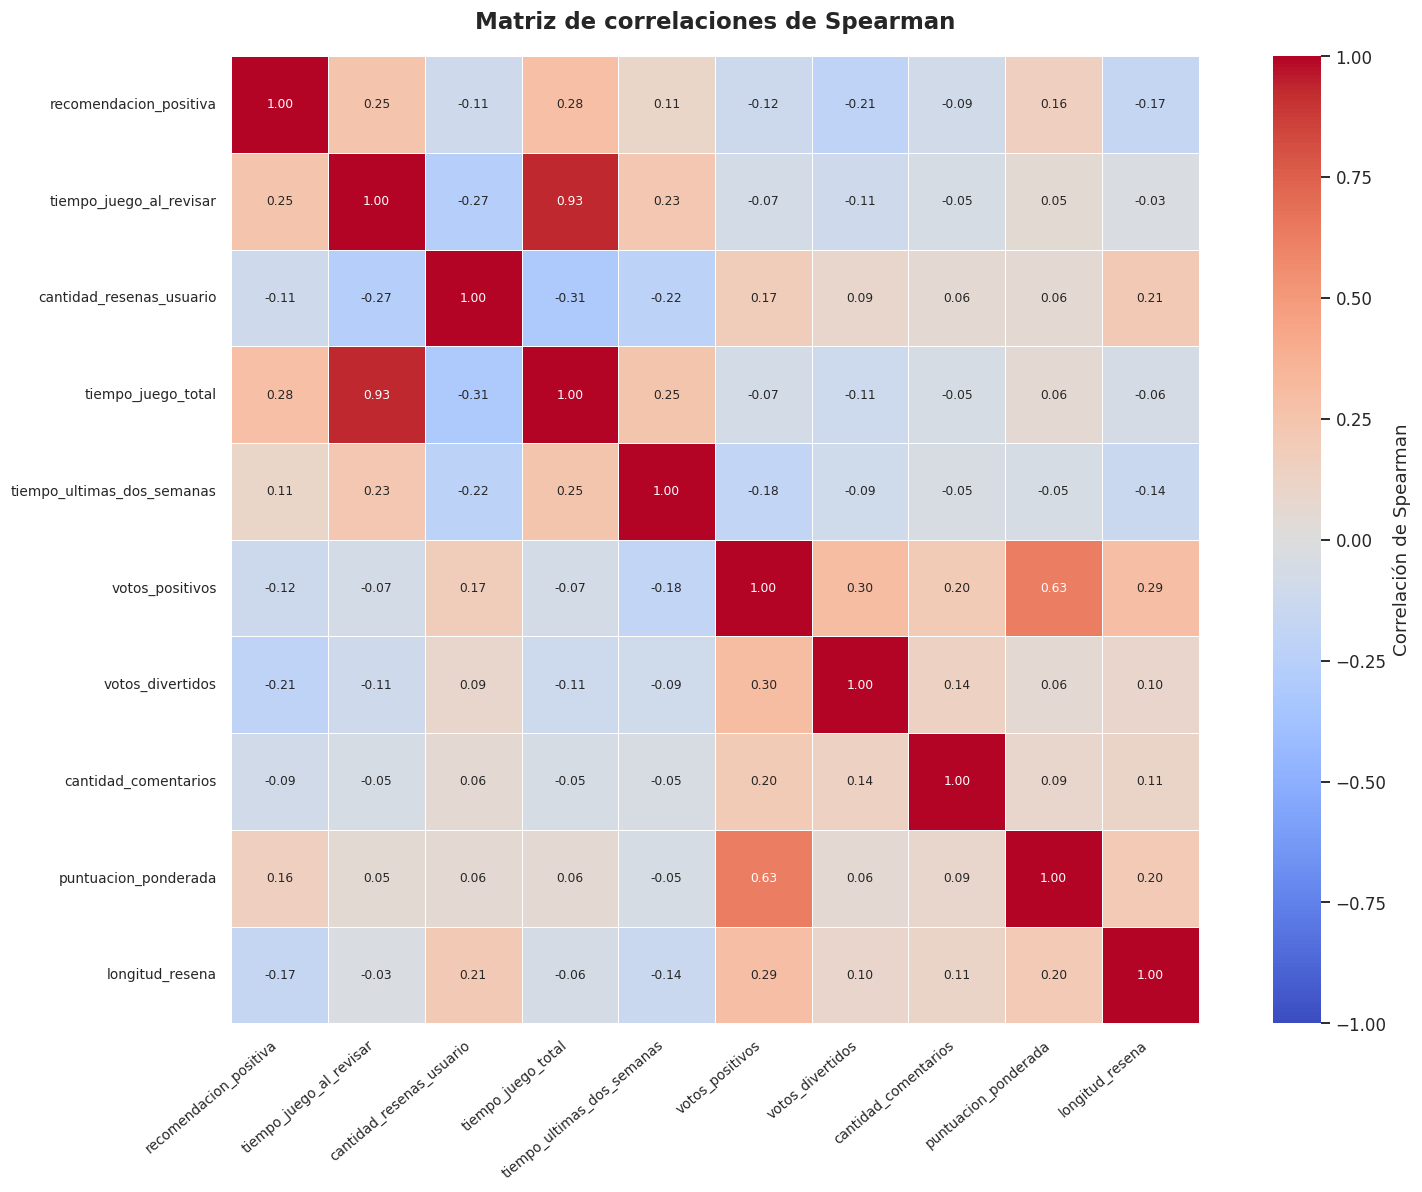

[OK] 08_matriz_correlaciones_spearman.png

RESULTADOS EXPORTADOS
/content/drive/MyDrive/Infraestructura-de-ciencia-de-datos/Analytics/Reports/EDA_Estadistica

ANÁLISIS DE CORRELACIONES FINALIZADO


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [12]:

# ============================================================
# STEAM ANALYTICS
# NOTEBOOK 1 - CELDA 8
# ANÁLISIS DE CORRELACIONES - SPEARMAN
# ============================================================

print("=" * 85)
print("ANÁLISIS DE CORRELACIONES")
print("=" * 85)

# ------------------------------------------------------------
# 1. CONSTRUIR UNA MUESTRA POR USUARIO
# ------------------------------------------------------------

columnas = [
    "recommendationid",
    "user_key",
    "game_key",
    "timestamp_created_parsed",
    "voted_up",
    "review",
    "votes_up",
    "votes_funny",
    "comment_count",
    "weighted_vote_score",
    "author.playtime_at_review",
    "author.num_reviews",
    "author.playtime_forever",
    "author.playtime_last_two_weeks"
]

correlacion_base = df_resenas[columnas].copy()

correlacion_base["fecha"] = pd.to_datetime(
    correlacion_base["timestamp_created_parsed"],
    errors="coerce",
    utc=True
)

correlacion_base = correlacion_base[
    (correlacion_base["user_key"] > 0) &
    correlacion_base["fecha"].notna() &
    correlacion_base["voted_up"].notna()
].copy()

correlacion_base = (
    correlacion_base
    .sort_values(["fecha", "recommendationid"])
    .drop_duplicates("user_key", keep="last")
    .copy()
)

print(f"Usuarios analizados: {len(correlacion_base):,}")

# ------------------------------------------------------------
# 2. PREPARAR VARIABLES NUMÉRICAS
# ------------------------------------------------------------

correlaciones = pd.DataFrame(index=correlacion_base.index)

correlaciones["recomendacion_positiva"] = (
    correlacion_base["voted_up"].astype(int)
)

variables = {
    "tiempo_juego_al_revisar": "author.playtime_at_review",
    "cantidad_resenas_usuario": "author.num_reviews",
    "tiempo_juego_total": "author.playtime_forever",
    "tiempo_ultimas_dos_semanas": "author.playtime_last_two_weeks",
    "votos_positivos": "votes_up",
    "votos_divertidos": "votes_funny",
    "cantidad_comentarios": "comment_count",
    "puntuacion_ponderada": "weighted_vote_score"
}

for nombre, columna in variables.items():
    correlaciones[nombre] = pd.to_numeric(
        correlacion_base[columna],
        errors="coerce"
    )

correlaciones["longitud_resena"] = (
    correlacion_base["review"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.len()
)

correlaciones = correlaciones.replace(
    [np.inf, -np.inf], np.nan
)

# ------------------------------------------------------------
# 3. MATRIZ SPEARMAN
# ------------------------------------------------------------

matriz_spearman = correlaciones.corr(
    method="spearman",
    min_periods=30
)

print("\n1. MATRIZ DE CORRELACIONES")
display(matriz_spearman.round(3))

# ------------------------------------------------------------
# 4. CORRELACIONES POR PARES Y VALORES P
# ------------------------------------------------------------

resultados_correlacion = []

columnas = list(correlaciones.columns)

for i in range(len(columnas)):
    for j in range(i + 1, len(columnas)):

        var1 = columnas[i]
        var2 = columnas[j]

        par = correlaciones[[var1, var2]].dropna()

        if len(par) < 30:
            continue

        if par[var1].nunique() < 2 or par[var2].nunique() < 2:
            continue

        prueba = stats.spearmanr(
            par[var1],
            par[var2]
        )

        resultados_correlacion.append({
            "variable_1": var1,
            "variable_2": var2,
            "observaciones": len(par),
            "rho_spearman": float(prueba.statistic),
            "p_valor": float(prueba.pvalue)
        })

tabla_correlaciones = pd.DataFrame(
    resultados_correlacion
)

# Bonferroni sobre todos los pares evaluados
cantidad_pruebas = len(tabla_correlaciones)

tabla_correlaciones["p_ajustado"] = np.minimum(
    tabla_correlaciones["p_valor"] * cantidad_pruebas,
    1.0
)

tabla_correlaciones["asociacion"] = pd.cut(
    tabla_correlaciones["rho_spearman"].abs(),
    bins=[-0.001, 0.10, 0.30, 0.50, 1.001],
    labels=["Muy débil", "Débil", "Moderada", "Fuerte"]
)

tabla_correlaciones = tabla_correlaciones.sort_values(
    "rho_spearman",
    key=lambda x: x.abs(),
    ascending=False
)

print("\n2. ASOCIACIONES MÁS FUERTES")
display(tabla_correlaciones.head(20))

# ------------------------------------------------------------
# 5. RELACIONES CON LA RECOMENDACIÓN
# ------------------------------------------------------------

relacion_recomendacion = matriz_spearman[
    "recomendacion_positiva"
].drop("recomendacion_positiva").to_frame(
    name="rho_spearman"
)

relacion_recomendacion["magnitud"] = (
    relacion_recomendacion["rho_spearman"]
    .abs()
    .map(
        lambda x:
            "Muy débil" if x < 0.10 else
            "Débil" if x < 0.30 else
            "Moderada" if x < 0.50 else
            "Fuerte"
    )
)

relacion_recomendacion = (
    relacion_recomendacion
    .sort_values("rho_spearman", key=lambda x: x.abs(), ascending=False)
)

print("\n3. ASOCIACIONES CON RECOMENDACIÓN")
display(relacion_recomendacion)

# ------------------------------------------------------------
# 6. HEATMAP
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(15, 11))

sns.heatmap(
    matriz_spearman,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    annot_kws={"size": 8},
    cbar_kws={"label": "Correlación de Spearman"},
    ax=ax
)

ax.set_title(
    "Matriz de correlaciones de Spearman",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=40,
    ha="right",
    fontsize=9
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0,
    fontsize=9
)

guardar_figura(
    fig,
    "08_matriz_correlaciones_spearman.png"
)

# ------------------------------------------------------------
# 7. EXPORTAR RESULTADOS
# ------------------------------------------------------------

matriz_spearman.to_csv(
    REPORTS / "matriz_correlaciones_spearman.csv",
    encoding="utf-8-sig"
)

tabla_correlaciones.to_csv(
    REPORTS / "correlaciones_por_pares.csv",
    index=False,
    encoding="utf-8-sig"
)

relacion_recomendacion.to_csv(
    REPORTS / "correlaciones_recomendacion.csv",
    encoding="utf-8-sig"
)

print("\nRESULTADOS EXPORTADOS")
print(REPORTS)

print("\nANÁLISIS DE CORRELACIONES FINALIZADO")



## 10. Análisis de cohortes de usuarios (2020–2025)

### 10.1. Objetivo

Investigar las diferencias en el comportamiento de recomendación entre usuarios de Steam cuyas cuentas fueron creadas entre 2020 y 2025.

El análisis se concentra exclusivamente en seis cohortes anuales: 2020, 2021, 2022, 2023, 2024 y 2025.

### 10.2. Definición de cohorte

La cohorte se determina mediante la variable `account_created_year`, obtenida de la dimensión de usuarios.

Cada cohorte representa usuarios cuya cuenta fue creada durante un mismo año calendario.

### 10.3. Variables e indicadores

Se utilizarán:

- Año de creación de cuenta.
- Identificador de usuario.
- Resultado de la recomendación.

Se calcularán:

- Cantidad de usuarios por cohorte.
- Recomendaciones positivas y negativas.
- Proporción de recomendaciones positivas.
- Intervalos de confianza del 95 %.

### 10.4. Metodología

Se utilizará una observación por usuario, correspondiente a su reseña más reciente dentro de la muestra recolectada.

Se aplicará una prueba chi-cuadrado de independencia para evaluar la asociación entre año de creación de cuenta y recomendación.

Se calculará V de Cramér para estimar la magnitud de la asociación.

Se utilizarán intervalos de confianza de Wilson al 95 % para las proporciones de recomendaciones positivas.

### 10.5. Alcance temporal

El análisis principal incluye exclusivamente las cohortes 2020–2025.

Los usuarios creados antes de 2020 o durante 2026 quedan excluidos de las comparaciones principales.

La fecha de creación de cuenta determina la cohorte, independientemente del año en que se haya publicado la reseña seleccionada.

### 10.6. Limitaciones

El análisis utiliza una única reseña por usuario y no representa su trayectoria completa de recomendaciones.

Las diferencias observadas pueden estar relacionadas con características de los videojuegos y períodos de publicación.

No se establecerán relaciones causales a partir de las asociaciones observadas.

### 10.7. Resultado esperado

- Tabla de indicadores por cohorte.
- Intervalos de confianza.
- Tabla de contingencia.
- Contraste estadístico.
- Visualización de las seis cohortes.
- Conclusiones para el proyecto Steam Analytics.


ANÁLISIS DE COHORTES - PERÍODO 2020-2025

1. SELECCIÓN DE USUARIOS
Usuarios con reseñas: 38,999

2. COBERTURA DE LAS COHORTES
Período: 2020-2025
Usuarios antes del filtro: 38,999
Usuarios incluidos: 9,413
Usuarios excluidos: 29,586

3. RESULTADOS POR COHORTE


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,cohorte,usuarios,recomendaciones_positivas,recomendaciones_negativas,tasa_positiva_pct,ic_95_inferior_pct,ic_95_superior_pct
0,2020,2042,1744,298,85.410,83.810,86.870
1,2021,1577,1347,230,85.420,83.590,87.070
2,2022,1536,1344,192,87.500,85.750,89.060
3,2023,1379,1212,167,87.890,86.060,89.510
4,2024,1429,1248,181,87.330,85.510,88.960
5,2025,1450,1284,166,88.550,86.810,90.090



4. TABLA DE CONTINGENCIA


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


voted_up,Negativa,Positiva
cohorte,,
2020,298,1744
2021,230,1347
2022,192,1344
2023,167,1212
2024,181,1248
2025,166,1284



5. RESULTADOS DEL CONTRASTE
Cohortes: 6
Usuarios: 9,413
Chi-cuadrado: 12.4299
Grados de libertad: 5
Valor p: 2.93487608e-02
V de Cramér: 0.0363
Frecuencia esperada mínima: 180.78


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


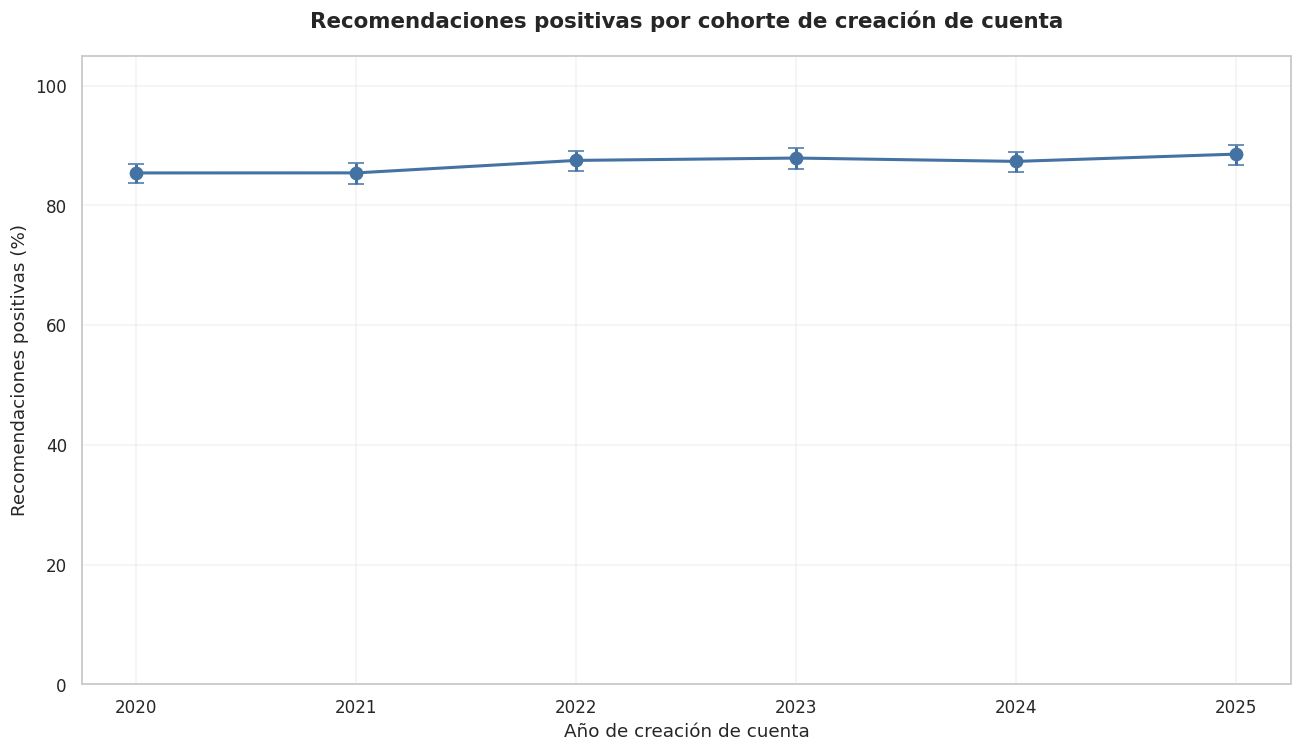

[OK] 09_recomendaciones_cohortes_2020_2025.png

6. ARCHIVOS GENERADOS
[OK] /content/drive/MyDrive/Infraestructura-de-ciencia-de-datos/Analytics/Reports/EDA_Estadistica/analisis_cohortes_2020_2025.csv
[OK] /content/drive/MyDrive/Infraestructura-de-ciencia-de-datos/Analytics/Reports/EDA_Estadistica/contingencia_cohortes_2020_2025.csv
[OK] /content/drive/MyDrive/Infraestructura-de-ciencia-de-datos/Analytics/Reports/EDA_Estadistica/contraste_cohortes_2020_2025.csv
[OK] /content/drive/MyDrive/Infraestructura-de-ciencia-de-datos/Analytics/Visualizations/EDA_Estadistica/09_recomendaciones_cohortes_2020_2025.png

ANÁLISIS DE COHORTES 2020-2025 FINALIZADO


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [14]:

# ============================================================
# STEAM ANALYTICS
# NOTEBOOK 1 - CELDA 9
# ANÁLISIS DE COHORTES 2020-2025
# ============================================================

print("=" * 85)
print("ANÁLISIS DE COHORTES - PERÍODO 2020-2025")
print("=" * 85)

# ------------------------------------------------------------
# 1. CONFIGURACIÓN DEL PERÍODO
# ------------------------------------------------------------

ANIO_INICIAL = 2020
ANIO_FINAL = 2025

ANIOS_COHORTE = list(
    range(ANIO_INICIAL, ANIO_FINAL + 1)
)

# ------------------------------------------------------------
# 2. PREPARACIÓN DE RESEÑAS
# ------------------------------------------------------------

cohortes_base = df_resenas[
    [
        "recommendationid",
        "user_key",
        "timestamp_created_parsed",
        "voted_up"
    ]
].copy()

cohortes_base["fecha_resena"] = pd.to_datetime(
    cohortes_base["timestamp_created_parsed"],
    errors="coerce",
    utc=True
)

cohortes_base["user_key"] = pd.to_numeric(
    cohortes_base["user_key"],
    errors="coerce"
)

cohortes_base = cohortes_base[
    (cohortes_base["user_key"] > 0) &
    cohortes_base["fecha_resena"].notna() &
    cohortes_base["voted_up"].notna()
].copy()

# Una reseña por usuario: la más reciente de la muestra.
cohortes_base = (
    cohortes_base
    .sort_values(
        ["fecha_resena", "recommendationid"]
    )
    .drop_duplicates(
        subset="user_key",
        keep="last"
    )
    .copy()
)

print("\n1. SELECCIÓN DE USUARIOS")
print(f"Usuarios con reseñas: {len(cohortes_base):,}")

# ------------------------------------------------------------
# 3. INCORPORAR AÑO DE CREACIÓN
# ------------------------------------------------------------

usuarios_cohorte = df_usuarios[
    ["user_key", "account_created_year"]
].copy()

usuarios_cohorte["account_created_year"] = pd.to_numeric(
    usuarios_cohorte["account_created_year"],
    errors="coerce"
)

if usuarios_cohorte["user_key"].duplicated().any():
    raise ValueError(
        "dim_usuarios contiene user_key duplicados."
    )

cohortes_base = cohortes_base.merge(
    usuarios_cohorte,
    on="user_key",
    how="left",
    validate="one_to_one"
)

# ------------------------------------------------------------
# 4. FILTRAR EXCLUSIVAMENTE 2020-2025
# ------------------------------------------------------------

usuarios_antes_filtro = cohortes_base["user_key"].nunique()

cohortes_base = cohortes_base[
    cohortes_base["account_created_year"].between(
        ANIO_INICIAL,
        ANIO_FINAL
    )
].copy()

cohortes_base["cohorte"] = (
    cohortes_base["account_created_year"].astype(int)
)

usuarios_periodo = cohortes_base["user_key"].nunique()

print("\n2. COBERTURA DE LAS COHORTES")
print(f"Período: {ANIO_INICIAL}-{ANIO_FINAL}")
print(f"Usuarios antes del filtro: {usuarios_antes_filtro:,}")
print(f"Usuarios incluidos: {usuarios_periodo:,}")
print(f"Usuarios excluidos: {usuarios_antes_filtro - usuarios_periodo:,}")

if cohortes_base.empty:
    raise ValueError(
        "No existen usuarios para el período 2020-2025."
    )

if not set(cohortes_base["cohorte"].unique()).issubset(
    set(ANIOS_COHORTE)
):
    raise ValueError("Se detectaron cohortes fuera del período.")

# ------------------------------------------------------------
# 5. CALCULAR INDICADORES POR COHORTE
# ------------------------------------------------------------

cohortes = (
    cohortes_base
    .groupby("cohorte")
    .agg(
        usuarios=("user_key", "nunique"),
        recomendaciones_positivas=("voted_up", "sum")
    )
)

# Mantener siempre los seis años en el informe.
cohortes = cohortes.reindex(
    ANIOS_COHORTE,
    fill_value=0
)

cohortes = cohortes.reset_index()

cohortes["recomendaciones_negativas"] = (
    cohortes["usuarios"] -
    cohortes["recomendaciones_positivas"]
)

cohortes["tasa_positiva"] = np.divide(
    cohortes["recomendaciones_positivas"],
    cohortes["usuarios"],
    out=np.full(len(cohortes), np.nan),
    where=cohortes["usuarios"].to_numpy() > 0
)

# ------------------------------------------------------------
# 6. INTERVALOS DE CONFIANZA WILSON 95%
# ------------------------------------------------------------

z = stats.norm.ppf(0.975)

n = cohortes["usuarios"].to_numpy(dtype=float)
p = cohortes["tasa_positiva"].to_numpy(dtype=float)

denominador = 1 + (z ** 2 / n)

centro = (
    p + (z ** 2 / (2 * n))
) / denominador

margen = (
    z * np.sqrt(
        (p * (1 - p) / n) +
        (z ** 2 / (4 * n ** 2))
    ) / denominador
)

cohortes["ic_95_inferior"] = centro - margen
cohortes["ic_95_superior"] = centro + margen

cohortes["tasa_positiva_pct"] = (
    cohortes["tasa_positiva"] * 100
)

cohortes["ic_95_inferior_pct"] = (
    cohortes["ic_95_inferior"] * 100
)

cohortes["ic_95_superior_pct"] = (
    cohortes["ic_95_superior"] * 100
)

# ------------------------------------------------------------
# 7. PRESENTACIÓN DE RESULTADOS
# ------------------------------------------------------------

print("\n3. RESULTADOS POR COHORTE")

COLUMNAS_SALIDA = [
    "cohorte",
    "usuarios",
    "recomendaciones_positivas",
    "recomendaciones_negativas",
    "tasa_positiva_pct",
    "ic_95_inferior_pct",
    "ic_95_superior_pct"
]

display(
    cohortes[COLUMNAS_SALIDA].round(2)
)

# ------------------------------------------------------------
# 8. TABLA DE CONTINGENCIA
# ------------------------------------------------------------

tabla_cohortes = pd.crosstab(
    cohortes_base["cohorte"],
    cohortes_base["voted_up"]
).reindex(
    index=ANIOS_COHORTE,
    columns=[False, True],
    fill_value=0
)

tabla_cohortes.index.name = "cohorte"

tabla_cohortes = tabla_cohortes.rename(
    columns={
        False: "Negativa",
        True: "Positiva"
    }
)

print("\n4. TABLA DE CONTINGENCIA")
display(tabla_cohortes)

# ------------------------------------------------------------
# 9. PRUEBA CHI-CUADRADO
# ------------------------------------------------------------

if (cohortes["usuarios"] == 0).any():
    raise ValueError(
        "Hay cohortes sin usuarios. Revisar la cobertura temporal."
    )

chi2, p_valor, grados, esperados = (
    stats.chi2_contingency(
        tabla_cohortes,
        correction=False
    )
)

n_total = int(tabla_cohortes.to_numpy().sum())

cramers_v = np.sqrt(
    chi2 / (
        n_total *
        min(
            tabla_cohortes.shape[0] - 1,
            tabla_cohortes.shape[1] - 1
        )
    )
)

print("\n5. RESULTADOS DEL CONTRASTE")
print(f"Cohortes: {len(ANIOS_COHORTE)}")
print(f"Usuarios: {n_total:,}")
print(f"Chi-cuadrado: {chi2:.4f}")
print(f"Grados de libertad: {grados}")
print(f"Valor p: {p_valor:.8e}")
print(f"V de Cramér: {cramers_v:.4f}")
print(f"Frecuencia esperada mínima: {esperados.min():.2f}")

if esperados.min() < 5:
    print(
        "ADVERTENCIA: la aproximación chi-cuadrado "
        "puede no ser adecuada."
    )

# ------------------------------------------------------------
# 10. VISUALIZACIÓN DE COHORTES 2020-2025
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 7))

ax.errorbar(
    cohortes["cohorte"],
    cohortes["tasa_positiva_pct"],
    yerr=[
        cohortes["tasa_positiva_pct"] -
        cohortes["ic_95_inferior_pct"],
        cohortes["ic_95_superior_pct"] -
        cohortes["tasa_positiva_pct"]
    ],
    fmt="o-",
    markersize=8,
    capsize=5,
    linewidth=2,
    color="#4472A3"
)

ax.set_xticks(ANIOS_COHORTE)
ax.set_xticklabels(
    ANIOS_COHORTE,
    fontsize=11
)

ax.set_title(
    "Recomendaciones positivas por cohorte de creación de cuenta",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Año de creación de cuenta")
ax.set_ylabel("Recomendaciones positivas (%)")

ax.set_ylim(0, 105)
ax.grid(alpha=0.25)

guardar_figura(
    fig,
    "09_recomendaciones_cohortes_2020_2025.png"
)

# ------------------------------------------------------------
# 11. EXPORTAR RESULTADOS DEL PERÍODO PRINCIPAL
# ------------------------------------------------------------

resumen_cohortes = pd.DataFrame([{
    "periodo_cohortes": "2020-2025",
    "cantidad_cohortes": len(ANIOS_COHORTE),
    "usuarios_analizados": n_total,
    "chi2": chi2,
    "grados_libertad": grados,
    "p_valor": p_valor,
    "cramers_v": cramers_v,
    "frecuencia_esperada_minima": esperados.min()
}])

cohortes.to_csv(
    REPORTS / "analisis_cohortes_2020_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

tabla_cohortes.to_csv(
    REPORTS / "contingencia_cohortes_2020_2025.csv",
    encoding="utf-8-sig"
)

resumen_cohortes.to_csv(
    REPORTS / "contraste_cohortes_2020_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n6. ARCHIVOS GENERADOS")

for archivo in [
    "analisis_cohortes_2020_2025.csv",
    "contingencia_cohortes_2020_2025.csv",
    "contraste_cohortes_2020_2025.csv"
]:
    print(f"[OK] {REPORTS / archivo}")

print(
    f"[OK] {VISUALIZATIONS / '09_recomendaciones_cohortes_2020_2025.png'}"
)

print("\nANÁLISIS DE COHORTES 2020-2025 FINALIZADO")
print("=" * 85)


In [15]:

# ============================================================
# STEAM ANALYTICS
# NOTEBOOK 1 - CELDA 10
# CORRECCIÓN GLOBAL DE HIPÓTESIS
# ============================================================

print("=" * 85)
print("CORRECCIÓN GLOBAL - TRES HIPÓTESIS PRINCIPALES")
print("=" * 85)

# ------------------------------------------------------------
# 1. CARGAR RESULTADOS ORIGINALES
# ------------------------------------------------------------

ruta_h12 = REPORTS / "resultados_contraste_hipotesis.csv"
ruta_h3 = REPORTS / "contraste_cohortes_2020_2025.csv"

if not ruta_h12.exists() or not ruta_h3.exists():
    raise FileNotFoundError(
        "Faltan los informes originales de hipótesis."
    )

h12 = pd.read_csv(ruta_h12)
h3 = pd.read_csv(ruta_h3)

# ------------------------------------------------------------
# 2. UNIFICAR LOS TRES CONTRASTES
# ------------------------------------------------------------

global_tests = pd.DataFrame({
    "hipotesis": h12["hipotesis"],
    "pregunta": h12["pregunta"],
    "metodo": h12["metodo"],
    "p_valor_original": pd.to_numeric(
        h12["p_valor"], errors="coerce"
    )
})

fila_h3 = pd.DataFrame([{
    "hipotesis": "H3",
    "pregunta": "Año de creación de cuenta y recomendación",
    "metodo": "Chi-cuadrado de independencia",
    "p_valor_original": float(h3["p_valor"].iloc[0])
}])

global_tests = pd.concat(
    [global_tests, fila_h3],
    ignore_index=True
)

# Validar que realmente se estén evaluando tres hipótesis.
if len(global_tests) != 3:
    raise ValueError(
        f"Se esperaban 3 hipótesis y se encontraron {len(global_tests)}."
    )

if global_tests["p_valor_original"].isna().any():
    raise ValueError("Hay valores p nulos o inválidos.")

# ------------------------------------------------------------
# 3. BONFERRONI GLOBAL
# ------------------------------------------------------------

NUMERO_HIPOTESIS = len(global_tests)
ALPHA = 0.05

global_tests["p_ajustado_global"] = np.minimum(
    global_tests["p_valor_original"] * NUMERO_HIPOTESIS,
    1.0
)

global_tests["significativo_sin_ajuste"] = (
    global_tests["p_valor_original"] < ALPHA
)

global_tests["significativo_con_ajuste"] = (
    global_tests["p_ajustado_global"] < ALPHA
)

global_tests["decision_global"] = np.where(
    global_tests["significativo_con_ajuste"],
    "Rechazar H0",
    "No rechazar H0"
)

global_tests["observacion_numerica"] = np.where(
    global_tests["p_valor_original"] == 0,
    "El cálculo devolvió 0 por límite de precisión numérica",
    "Valor p calculado normalmente"
)

# ------------------------------------------------------------
# 4. PRESENTACIÓN
# ------------------------------------------------------------

print("\nRESULTADOS COMPARATIVOS")
display(global_tests)

print("\nRESUMEN")
print(f"Hipótesis evaluadas: {NUMERO_HIPOTESIS}")
print(f"Nivel de significación: {ALPHA}")

for _, fila in global_tests.iterrows():

    print(
        f"\n{fila['hipotesis']} - {fila['pregunta']}"
    )

    print(
        f"p original: {fila['p_valor_original']:.8e}"
    )

    print(
        f"p ajustado: {fila['p_ajustado_global']:.8e}"
    )

    print(
        f"Decisión: {fila['decision_global']}"
    )

# ------------------------------------------------------------
# 5. EXPORTAR RESULTADO
# ------------------------------------------------------------

salida_global = REPORTS / "contraste_global_tres_hipotesis.csv"

global_tests.to_csv(
    salida_global,
    index=False,
    encoding="utf-8-sig"
)

print("\nARCHIVO GENERADO")
print(salida_global)

print("\nCORRECCIÓN GLOBAL FINALIZADA")
print("=" * 85)


CORRECCIÓN GLOBAL - TRES HIPÓTESIS PRINCIPALES

RESULTADOS COMPARATIVOS


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,hipotesis,pregunta,metodo,p_valor_original,p_ajustado_global,significativo_sin_ajuste,significativo_con_ajuste,decision_global,observacion_numerica
0,H1,Tiempo de juego y recomendación,Mann-Whitney U,0.000,0.000,True,True,Rechazar H0,El cálculo devolvió 0 por límite de precisión ...
1,H2,Idioma y recomendación,Chi-cuadrado de independencia,0.000,0.000,True,True,Rechazar H0,Valor p calculado normalmente
2,H3,Año de creación de cuenta y recomendación,Chi-cuadrado de independencia,0.029,0.088,True,False,No rechazar H0,Valor p calculado normalmente



RESUMEN
Hipótesis evaluadas: 3
Nivel de significación: 0.05

H1 - Tiempo de juego y recomendación
p original: 0.00000000e+00
p ajustado: 0.00000000e+00
Decisión: Rechazar H0

H2 - Idioma y recomendación
p original: 5.48780685e-48
p ajustado: 1.64634206e-47
Decisión: Rechazar H0

H3 - Año de creación de cuenta y recomendación
p original: 2.93487608e-02
p ajustado: 8.80462824e-02
Decisión: No rechazar H0

ARCHIVO GENERADO
/content/drive/MyDrive/Infraestructura-de-ciencia-de-datos/Analytics/Reports/EDA_Estadistica/contraste_global_tres_hipotesis.csv

CORRECCIÓN GLOBAL FINALIZADA


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



## 10.8. Corrección global de los contrastes estadísticos

Se aplicó una corrección global de Bonferroni sobre las tres hipótesis principales del proyecto, utilizando un nivel de significación de 0,05.

Esta corrección permite controlar el error familiar asociado a la realización de múltiples contrastes.

### Resultados

**H1 — Tiempo de juego y recomendación**

La evidencia estadística permanece significativa después de la corrección global. El cálculo original presentó una limitación de precisión numérica al devolver un valor p igual a cero, que no debe interpretarse como una probabilidad matemáticamente nula.

**H2 — Idioma y recomendación**

El valor p ajustado global es aproximadamente 1,65 × 10⁻⁴⁷. La asociación continúa siendo estadísticamente significativa, aunque su magnitud es pequeña.

**H3 — Cohortes 2020–2025 y recomendación**

El valor p original es aproximadamente 0,02935 y el ajustado global es aproximadamente 0,08805.

Por lo tanto, no se rechaza la hipótesis nula al aplicar la corrección global.

### Conclusión

Las hipótesis H1 y H2 conservan evidencia estadística después de la corrección global de Bonferroni.

La hipótesis H3 presenta una diferencia descriptiva entre las cohortes 2020–2025, pero no alcanza significación estadística después del ajuste global.

Las tasas de recomendaciones positivas por cohorte deben conservarse como resultados descriptivos y exploratorios.

La corrección aplicada refuerza la rigurosidad de las conclusiones y evita presentar como concluyentes asociaciones que no superan el criterio estadístico establecido.



# 11. Conclusiones finales — EDA y Estadística Aplicada

## 11.1. Caracterización general

Se analizaron 46.990 reseñas correspondientes a 38.999 usuarios y 497 videojuegos.

La muestra presenta:

- 79,53 % de recomendaciones positivas.
- 20,47 % de recomendaciones negativas.
- Predominio del idioma inglés (56,66 %).
- 46.838 reseñas con contenido textual.
- Cobertura temporal entre octubre de 2010 y noviembre de 2026.

La auditoría confirmó la conservación de todos los identificadores entre Silver y Gold.

## 11.2. Resultados de los contrastes principales

### H1. Tiempo de juego y recomendación

La prueba U de Mann-Whitney identificó diferencias entre las distribuciones de tiempo de juego al momento de publicar reseñas positivas y negativas.

- Mediana positiva: 528 minutos.
- Mediana negativa: 170 minutos.
- Correlación biserial de rangos: 0,3714.

La diferencia presentó una magnitud moderada y evidencia estadística suficiente después de la corrección global.

### H2. Idioma y recomendación

La prueba chi-cuadrado identificó una asociación entre el idioma de la reseña y el resultado de la recomendación.

- Chi-cuadrado: 278,2935.
- V de Cramér: 0,0845.
- Valor p original: 5,49 × 10⁻⁴⁸.
- Valor p ajustado global: 1,65 × 10⁻⁴⁷.

La asociación fue estadísticamente significativa, aunque de magnitud pequeña.

### H3. Cohortes 2020–2025 y recomendación

Se analizaron 9.413 usuarios pertenecientes a las seis cohortes principales.

Las tasas de recomendaciones positivas fueron:

- 2020: 85,41 %.
- 2021: 85,42 %.
- 2022: 87,50 %.
- 2023: 87,89 %.
- 2024: 87,33 %.
- 2025: 88,55 %.

El contraste chi-cuadrado presentó:

- Chi-cuadrado: 12,4299.
- Grados de libertad: 5.
- Valor p original: 0,02935.
- V de Cramér: 0,0363.
- Valor p ajustado global: 0,08805.

Aunque se observa una diferencia descriptiva entre cohortes, no se alcanza significación estadística al aplicar la corrección global de Bonferroni.

## 11.3. Corrección global de hipótesis

Se aplicó la corrección de Bonferroni a los tres contrastes principales:

| Hipótesis | Resultado global |
|---|---|
| H1 - Tiempo de juego | Significativa |
| H2 - Idioma | Significativa |
| H3 - Cohortes 2020–2025 | No significativa |

El valor p de H1 presentó subdesbordamiento numérico en SciPy, por lo que el resultado almacenado como cero no debe interpretarse como una probabilidad matemáticamente nula.

Los análisis exploratorios de correlación utilizaron su propia corrección por comparaciones múltiples y no forman parte de esta familia de tres contrastes principales.

## 11.4. Principales correlaciones identificadas

El análisis de Spearman permitió identificar:

- Tiempo al revisar y tiempo total de juego: ρ = 0,933.
- Votos positivos y puntuación ponderada: ρ = 0,629.
- Tiempo total y recomendación positiva: ρ = 0,284.
- Tiempo al revisar y recomendación positiva: ρ = 0,254.

Se identificaron relaciones redundantes entre variables y posibles características útiles para futuros experimentos predictivos.

## 11.5. Hallazgos relevantes

1. El tiempo de juego presenta una asociación con el resultado de la recomendación.
2. El idioma presenta una asociación estadística pequeña con la recomendación.
3. Las diferencias entre cohortes 2020–2025 no superan el criterio de significación global.
4. Las variables de interacción presentan asociaciones que merecen estudiarse en profundidad.
5. La longitud de las reseñas presenta una distribución asimétrica.
6. La composición de la muestra y sus límites de extracción condicionan la interpretación de los resultados.

## 11.6. Limitaciones metodológicas

- La muestra no representa la totalidad de las reseñas de Steam.
- Se configuró un límite de 100 reseñas por juego, aunque se identificaron seis excepciones.
- 5.911 usuarios no poseen información de creación de cuenta.
- La información de hardware está ausente en la mayoría de las reseñas.
- Los usuarios pueden compartir videojuegos, por lo que existe posible dependencia entre observaciones.
- Las variables de interacción pueden actualizarse después de publicar las reseñas.
- Las asociaciones estadísticas no demuestran causalidad.
- El análisis de cohortes utiliza exclusivamente 2020–2025 como período principal.

## 11.7. Conclusión general

El análisis exploratorio y estadístico permitió caracterizar la muestra, identificar patrones de comportamiento, estudiar relaciones entre variables y contrastar hipótesis.

Se obtuvieron resultados estadísticos relevantes y se documentaron las limitaciones necesarias para evitar interpretaciones incorrectas.

Los hallazgos proporcionan una base para seleccionar variables, formular problemas predictivos y desarrollar experimentos de procesamiento de lenguaje natural y Machine Learning.

## 11.8. Estado final

**Notebook 1 — EDA + Estadística Aplicada: COMPLETADO.**

Los informes, tablas y visualizaciones se encuentran almacenados en las carpetas correspondientes de Analytics.
